# NLP Group Assignment 2 · Question 1
## Attention-Based Neural Machine Translation: English -> Hindi (IIT Bombay corpus)

###
| Part | Content |
|---|---|
| 1 | Data preparation (IITB corpus, cleaning, Unicode-safe tokenisation, vocab, padding, statistics) |
| 2 | Baseline: LSTM encoder–decoder **without** attention, teacher forcing |
| 3 | Baseline limitation study (short vs long sentences, position-wise recall proxy) |
| 4 | **Manually implemented Bahdanau (additive) attention**, inspectable weights, correct pad masking |
| 5 | Train both models under matched conditions; loss/accuracy curves; BLEU / chrF; paired bootstrap |
| 6 | Attention heat-maps (x = English, y = generated Hindi) + quantitative attention diagnostics |
| 7 | Error analysis of ≥ 5 incorrect test translations (baseline vs attention, heat-maps, error flags) |
| 8 | Performance by sentence length (1–5, 6–10, 11–15, 16+) with plots |
| 9 | Final comparative analysis  |



## 0 · Setup & configuration

In [1]:
# ---- 0.1 imports / optional installs --------------------------------------------------
import os, sys, re, io, json, math, time, random, glob, hashlib, subprocess, unicodedata, warnings
from collections import Counter, defaultdict
from dataclasses import dataclass

def _ensure(pkg, import_name=None):
    try:
        __import__(import_name or pkg)
    except ImportError:
        print(f"Installing {pkg} ...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])

_ensure("datasets"); _ensure("sacrebleu"); _ensure("pandas"); _ensure("matplotlib")

import numpy as np
import pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence, pad_sequence
from torch.utils.data import Dataset, DataLoader
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import font_manager as fm
from IPython.display import display, HTML
import sacrebleu
from sacrebleu.metrics import BLEU, CHRF
try:
    from tqdm.auto import tqdm
except Exception:
    def tqdm(x, **kw): return x
warnings.filterwarnings("ignore", category=UserWarning)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch", torch.__version__, "| matplotlib", matplotlib.__version__, "| sacrebleu", sacrebleu.__version__)
print("device:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "NO GPU – training will be slow; consider Colab GPU")

Installing sacrebleu ...
torch 2.11.0+cu130 | matplotlib 3.10.0 | sacrebleu 2.6.0
device: cuda | Tesla T4


In [2]:
# ---- 0.2 configuration -----------------------------------------------------
CFG = dict(
    smoke_test      = os.environ.get("NMT_SMOKE", "0") == "1",  # True => synthetic toy data, tiny model (pipeline check only!)
    seed            = 42,
    # data
    hf_dataset      = "cfilt/iitb-english-hindi",
    local_dir       = None,       # optional: folder with official IITB files (see load_local_iitb docstring)
    train_pairs     = 50_000,     # size of the training subset
    pool_factor     = 3,          # sample train_pairs*pool_factor raw pairs, then clean/filter, then keep train_pairs
    max_len_train   = 40,         # max tokens per side (excl. <SOS>/<EOS>) for training pairs
    max_len_eval    = 60,         # max tokens per side for validation / test pairs (longer ones are dropped & counted)
    max_len_ratio   = 3.0,        # drop pairs whose token-length ratio exceeds this (only if the longer side >= 4 tokens)
    min_freq        = 2,          # vocabulary minimum frequency (train only)
    max_vocab       = 20_000,     # cap per language (incl. special tokens)
    # model (identical for A and B)
    emb_dim         = 256,
    hid_dim         = 256,        # encoder hidden size per direction AND decoder hidden size
    attn_dim        = 256,
    enc_layers      = 1,
    enc_bidirectional = True,
    dropout         = 0.3,
    # training (identical for A and B)
    batch_size      = 128,
    epochs          = 15,
    lr              = 1e-3,
    clip            = 1.0,
    patience        = 3,          # early stopping on validation loss
    tf_ratio        = 1.0,        # 1.0 = full teacher forcing
    use_amp         = True,       # mixed precision on CUDA
    reuse_checkpoints = True,     # reload finished runs from out_dir if the config signature matches
    # evaluation
    max_decode_len  = 60,
    length_buckets  = [(1, 5), (6, 10), (11, 15), (16, None)],
    n_bootstrap     = 200,
    n_heatmaps      = 4,
    n_error_cases   = 8,          # >= 5 required
    # outputs
    out_dir         = "nmt_outputs",
    mount_drive     = False,      # Colab only: save outputs to /content/drive/MyDrive/nmt_outputs
    install_hindi_font = True,    # try apt-get install of a Devanagari font if none is found
)

if CFG["smoke_test"]:     # tiny, fast, SYNTHETIC. Only checks that the code runs.
    CFG.update(train_pairs=1500, max_len_train=40, max_len_eval=60, emb_dim=32, hid_dim=32, attn_dim=32,
               batch_size=32, epochs=2, patience=2, n_bootstrap=10, n_heatmaps=2, n_error_cases=6,
               max_decode_len=45, reuse_checkpoints=False, install_hindi_font=False, out_dir="nmt_outputs_SMOKE")
    print("\n" + "!"*88 + "\n!! SMOKE TEST MODE: synthetic data, tiny model. Results are MEANINGLESS. NOT the IITB corpus. !!\n" + "!"*88)

if CFG["mount_drive"]:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        CFG["out_dir"] = "/content/drive/MyDrive/nmt_outputs"
    except Exception as e:
        print("Drive mount failed, using local out_dir:", e)
os.makedirs(CFG["out_dir"], exist_ok=True)

# ---- 0.3 reproducibility ----------------------------------------------------------------
def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
set_seed(CFG["seed"])
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
print("Seed:", CFG["seed"], "(note: bit-exact GPU reproducibility is not guaranteed with AMP/cuDNN atomics)")
print(json.dumps({k: v for k, v in CFG.items()}, indent=1, default=str))

Seed: 42 (note: bit-exact GPU reproducibility is not guaranteed with AMP/cuDNN atomics)
{
 "smoke_test": false,
 "seed": 42,
 "hf_dataset": "cfilt/iitb-english-hindi",
 "local_dir": null,
 "train_pairs": 50000,
 "pool_factor": 3,
 "max_len_train": 40,
 "max_len_eval": 60,
 "max_len_ratio": 3.0,
 "min_freq": 2,
 "max_vocab": 20000,
 "emb_dim": 256,
 "hid_dim": 256,
 "attn_dim": 256,
 "enc_layers": 1,
 "enc_bidirectional": true,
 "dropout": 0.3,
 "batch_size": 128,
 "epochs": 15,
 "lr": 0.001,
 "clip": 1.0,
 "patience": 3,
 "tf_ratio": 1.0,
 "use_amp": true,
 "reuse_checkpoints": true,
 "max_decode_len": 60,
 "length_buckets": [
  [
   1,
   5
  ],
  [
   6,
   10
  ],
  [
   11,
   15
  ],
  [
   16,
   null
  ]
 ],
 "n_bootstrap": 200,
 "n_heatmaps": 4,
 "n_error_cases": 8,
 "out_dir": "nmt_outputs",
 "mount_drive": false,
 "install_hindi_font": true
}


### Hindi font for plots
Matplotlib needs a font that contains **Devanagari** glyphs, otherwise Hindi tick labels become empty boxes.


Pillow Raqm shaping available: True


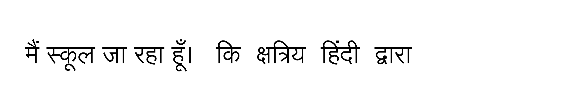

In [7]:
from PIL import Image, ImageDraw, ImageFont, features
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
RAQM_OK = bool(features.check("raqm"))
HINDI_FONT_PATH = fm.findfont(fm.FontProperties(family=HINDI_FONT), fallback_to_default=True)
_RAQM = getattr(getattr(ImageFont, "Layout", ImageFont), "RAQM", getattr(ImageFont, "LAYOUT_RAQM", None))
DEVA_RE_PLOT = re.compile(r"[\u0900-\u097F]")
print("Pillow Raqm shaping available:", RAQM_OK)

_label_cache = {}
def shaped_text_image(text, px=64, color=(0, 0, 0)):
    key = (text, px, color)
    if key not in _label_cache:
        font = ImageFont.truetype(HINDI_FONT_PATH, px, layout_engine=_RAQM)
        asc, desc = font.getmetrics(); pad = px // 6
        w = int(math.ceil(font.getlength(text))) + 2 * pad
        img = Image.new("RGBA", (w, asc + desc + 2 * pad), (255, 255, 255, 0))
        ImageDraw.Draw(img).text((pad, pad), text, font=font, fill=color + (255,))
        _label_cache[key] = np.asarray(img)
    return _label_cache[key]

def add_shaped_ytick(ax, text, y, size_pt=11, px=64, xpad=-4):
    arr = shaped_text_image(text, px)
    zoom = (size_pt * ax.figure.dpi / 72.0) / px * 0.8
    ax.add_artist(AnnotationBbox(OffsetImage(arr, zoom=zoom), (0, y), xycoords=ax.get_yaxis_transform(),
                  boxcoords="offset points", xybox=(xpad, 0), box_alignment=(1, 0.5), frameon=False,
                  annotation_clip=False, pad=0))
    return arr.shape[1] * zoom * 72.0 / ax.figure.dpi

def draw_hindi(ax, xy, text, size_pt=16):
    arr = shaped_text_image(text, 96); zoom = (size_pt * ax.figure.dpi / 72.0) / 96 * 0.8
    ax.add_artist(AnnotationBbox(OffsetImage(arr, zoom=zoom), xy, xycoords="axes fraction", box_alignment=(0, 0.5), frameon=False))

fig, ax = plt.subplots(figsize=(7, 1.2)); ax.axis("off")
draw_hindi(ax, (0.02, 0.5), "मैं स्कूल जा रहा हूँ।   कि  क्षत्रिय  हिंदी  द्वारा")
plt.show()

## 1 · Part 1 – Data preparation

**Steps:** load pairs → normalise (Unicode-aware) → remove empty/malformed/duplicate pairs → tokenise → add `<SOS>`/`<EOS>` → build vocabularies (training split only) → integer IDs → pad per batch.

**Unicode notes (important for Hindi):**
* Hindi text is normalised with **NFC** (not NFKD/NFD, which would split precomposed characters); zero-width space / BOM are removed, ZWJ/ZWNJ are kept because they can be meaningful in Devanagari.
* Python's `\w` does **not** match Devanagari vowel signs (matras, category *Mc/Mn*), so `\w+` would cut Hindi words into pieces. The tokenizer therefore uses an explicit Devanagari range, and treats the danda `।` / double danda `॥` as separate punctuation tokens. This is checked by assertions below.
* English is NFKC-normalised and lower-cased. Hindi has no case.


In [8]:
# ---- 1.1 normalisation + tokenisation ---------------------------------------------------
ZERO_WIDTH_RE = re.compile("[​﻿]")                  # keep ZWJ(200d)/ZWNJ(200c)
CTRL_RE       = re.compile(r"[\x00-\x08\x0b-\x1f\x7f]")
WS_RE         = re.compile(r"\s+")
# word = Devanagari block (without danda U+0964/0965) + \w + joiners ; anything else non-space = single-char token
TOKEN_RE = re.compile(r"[\wऀ-ॣ०-ॿ‌‍]+|\S")

def normalize_en(s: str) -> str:
    s = unicodedata.normalize("NFKC", s).lower()
    s = ZERO_WIDTH_RE.sub("", CTRL_RE.sub(" ", s))
    return WS_RE.sub(" ", s).strip()

def normalize_hi(s: str) -> str:
    s = unicodedata.normalize("NFC", s)
    s = ZERO_WIDTH_RE.sub("", CTRL_RE.sub(" ", s))
    return WS_RE.sub(" ", s).strip()

def tokenize(s: str):
    return TOKEN_RE.findall(s)

# Unit tests: Hindi words must survive tokenisation intact
assert tokenize(normalize_hi("मैं स्कूल जा रहा हूँ।")) == ["मैं", "स्कूल", "जा", "रहा", "हूँ", "।"]
assert tokenize(normalize_hi("क्षत्रिय द्वारा कि")) == ["क्षत्रिय", "द्वारा", "कि"]
assert tokenize(normalize_hi("क़ताब")) == [normalize_hi("क़ताब")]      # nukta form stays one token
assert tokenize(normalize_en("I am going to school.")) == ["i", "am", "going", "to", "school", "."]
assert "".join(tokenize(normalize_hi("हिन्दी भाषा"))) == "हिन्दीभाषा"  # no characters lost
print("Tokenizer unit tests passed.")
print(tokenize(normalize_en("I am going to school.")), tokenize(normalize_hi("मैं स्कूल जा रहा हूँ।")))

Tokenizer unit tests passed.
['i', 'am', 'going', 'to', 'school', '.'] ['मैं', 'स्कूल', 'जा', 'रहा', 'हूँ', '।']


In [9]:
# ---- 1.2 corpus loaders -------------------------------------------------------------------
DEV_RE = re.compile(r"[ऀ-ॿ]"); LAT_RE = re.compile(r"[A-Za-z]")

def _pairs_from_hf_split(ds_split, idxs=None):
    """Return list of (en, hi) from a HF split. Handles `translation` dict column or flat en/hi columns."""
    sub = ds_split if idxs is None else ds_split.select(idxs)
    cols = sub.column_names
    if "translation" in cols:
        return [(d.get("en"), d.get("hi")) for d in sub["translation"]]
    if "en" in cols and "hi" in cols:
        return list(zip(sub["en"], sub["hi"]))
    raise ValueError(f"Unknown schema, columns = {cols}")

def load_hf_iitb(cfg, rng):
    from datasets import load_dataset
    last_err = None
    for kw in [dict(), dict(revision="refs/convert/parquet")]:     # second form: auto-converted parquet mirror
        try:
            ds = load_dataset(cfg["hf_dataset"], **kw)
            break
        except Exception as e:
            last_err = e; ds = None
    if ds is None:
        raise RuntimeError("Could not load the IITB corpus from the HF Hub. Download it from "
                           "https://www.cfilt.iitb.ac.in/iitb_parallel/ and set CFG['local_dir'] (see load_local_iitb). "
                           f"Last error: {last_err!r}")
    def pick(*names):
        for n in names:
            if n in ds: return ds[n]
        raise KeyError(f"none of {names} in {list(ds.keys())}")
    tr, va, te = pick("train"), pick("validation", "dev", "val"), pick("test")
    raw_sizes = dict(train=len(tr), validation=len(va), test=len(te))
    k = min(len(tr), cfg["train_pairs"] * cfg["pool_factor"])
    idxs = sorted(rng.sample(range(len(tr)), k))
    return dict(train=_pairs_from_hf_split(tr, idxs), val=_pairs_from_hf_split(va), test=_pairs_from_hf_split(te)), raw_sizes

def load_local_iitb(cfg, rng):
    """Local fallback. Expects parallel plain-text files (one sentence per line), e.g. from the official IITB release:
         <local_dir>/train.en  <local_dir>/train.hi   (e.g. copy/rename parallel/IITB.en-hi.en / .hi)
         <local_dir>/dev.en    <local_dir>/dev.hi
         <local_dir>/test.en   <local_dir>/test.hi
    """
    d = cfg["local_dir"]
    def rd(name):
        with open(os.path.join(d, name), encoding="utf-8") as f: return f.read().split("\n")
    out, sizes = {}, {}
    for key, fn in [("train", "train"), ("val", "dev"), ("test", "test")]:
        en, hi = rd(fn + ".en"), rd(fn + ".hi")
        n = min(len(en), len(hi))
        pairs = list(zip(en[:n], hi[:n]))
        sizes[key] = n
        if key == "train" and n > cfg["train_pairs"] * cfg["pool_factor"]:
            pairs = [pairs[i] for i in sorted(rng.sample(range(n), cfg["train_pairs"] * cfg["pool_factor"]))]
        out[key] = pairs
    return out, sizes

# ---- synthetic toy corpus: ONLY for the smoke test (pipeline check). It is NOT IITB data. ----
def make_synthetic(n, rng, rare_rate=0.03):
    adj = [("big", "बड़ा"), ("small", "छोटा"), ("old", "पुराना"), ("new", "नया"), ("red", "लाल"), ("kind", "दयालु")]
    noun = [("boy", "लड़का"), ("girl", "लड़की"), ("teacher", "शिक्षक"), ("doctor", "डॉक्टर"), ("farmer", "किसान"),
            ("book", "किताब"), ("house", "घर"), ("dog", "कुत्ता"), ("tree", "पेड़"), ("school", "स्कूल")]
    verb = [("sees", "देखता है"), ("likes", "पसंद करता है"), ("helps", "मदद करता है"), ("calls", "बुलाता है"), ("meets", "मिलता है")]
    rare = [(f"name{i}", f"नाम{chr(0x0915 + i % 20)}{chr(0x0915 + (i * 3) % 20)}") for i in range(60)]
    def np_():
        n_ = rng.choice(rare) if rng.random() < rare_rate else rng.choice(noun)
        a = rng.choice(adj) if rng.random() < 0.7 else None
        e = ["the"] + ([a[0]] if a else []) + [n_[0]]
        h = ([a[1]] if a else []) + [n_[1]]
        return e, h
    out = []
    for _ in range(n):
        e, h = [], []
        for c in range(rng.randint(1, 5)):                      # 1..5 clauses => variable lengths up to ~30 tokens
            s_e, s_h = np_(); o_e, o_h = np_(); v = rng.choice(verb)
            ce = s_e + [v[0]] + o_e; ch = s_h + o_h + [v[1]]
            if c: e += ["and"]; h += ["और"]
            e += ce; h += ch
        out.append((" ".join(e) + " .", " ".join(h) + " ।"))
    return out

def load_synthetic(cfg, rng):
    n = cfg["train_pairs"]
    d = dict(train=make_synthetic(n * cfg["pool_factor"], rng), val=make_synthetic(max(150, n // 10), rng),
             test=make_synthetic(max(300, n // 5), rng))
    return d, {k: len(v) for k, v in d.items()}

In [10]:
# ---- 1.3 load -> clean -> subsample -> statistics ------------------------------------------------
def clean_pairs(raw, max_len, max_ratio, name):
    """Normalise + filter. Returns list of dict(src_tok, tgt_tok) and a Counter of removal reasons."""
    stats, out, seen = Counter(), [], set()
    for en, hi in raw:
        if en is None or hi is None: stats["missing"] += 1; continue
        e, h = normalize_en(en), normalize_hi(hi)
        if not e or not h:                 stats["empty"] += 1; continue
        if not LAT_RE.search(e):           stats["no_latin_in_english"] += 1; continue
        if not DEV_RE.search(h):           stats["no_devanagari_in_hindi"] += 1; continue
        if (e, h) in seen:                 stats["duplicate_pair"] += 1; continue
        seen.add((e, h))
        et, ht = tokenize(e), tokenize(h)
        lo, hi_ = sorted((len(et), len(ht)))
        if hi_ >= 4 and hi_ / max(lo, 1) > max_ratio: stats["length_ratio"] += 1; continue
        if len(et) > max_len or len(ht) > max_len:     stats["too_long"] += 1; continue
        out.append(dict(src_tok=et, tgt_tok=ht))
    stats["kept"] = len(out)
    return out, stats

rng = random.Random(CFG["seed"])
if CFG["smoke_test"]:
    DATA_SOURCE = "SYNTHETIC (smoke test)"; raw, raw_sizes = load_synthetic(CFG, rng)
elif CFG["local_dir"]:
    DATA_SOURCE = f"local files in {CFG['local_dir']}"; raw, raw_sizes = load_local_iitb(CFG, rng)
else:
    DATA_SOURCE = f"HF Hub: {CFG['hf_dataset']}"; raw, raw_sizes = load_hf_iitb(CFG, rng)
print("Data source:", DATA_SOURCE)
print("Raw split sizes (before sampling/cleaning):", raw_sizes)

train_all, st_tr = clean_pairs(raw["train"], CFG["max_len_train"], CFG["max_len_ratio"], "train")
rng.shuffle(train_all)
train_items = train_all[:CFG["train_pairs"]]
val_items,  st_va = clean_pairs(raw["val"],  CFG["max_len_eval"], CFG["max_len_ratio"], "val")
test_items, st_te = clean_pairs(raw["test"], CFG["max_len_eval"], CFG["max_len_ratio"], "test")
if len(train_items) < CFG["train_pairs"]:
    print(f"NOTE: only {len(train_items)} training pairs survived cleaning (requested {CFG['train_pairs']}); increase pool_factor.")

print(f"\nCleaning report (train pool of {len(raw['train'])} sampled raw pairs): {dict(st_tr)}")
print(f"Cleaning report (validation, {len(raw['val'])} raw): {dict(st_va)}")
print(f"Cleaning report (test, {len(raw['test'])} raw): {dict(st_te)}")

# test/train exact-duplicate check (reported, not removed, to keep the official test set intact)
train_en_set = {" ".join(x["src_tok"]) for x in train_items}
dup_test = sum(" ".join(x["src_tok"]) in train_en_set for x in test_items)
print(f"\nTest sentences whose English side also occurs in the training subset: {dup_test} / {len(test_items)}")
for x in train_items[:3] + test_items[:2]:
    print("EN:", " ".join(x["src_tok"]), "\nHI:", " ".join(x["tgt_tok"]), "\n")

README.md:   0%|          | 0.00/3.14k [00:00<?, ?B/s]

dataset_infos.json:   0%|          | 0.00/953 [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  190MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 85.7kB            

data/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

... (2 outputs left out)

Generating train split:   0%|          | 0/1659083 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/520 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2507 [00:00<?, ? examples/s]

Data source: HF Hub: cfilt/iitb-english-hindi
Raw split sizes (before sampling/cleaning): {'train': 1659083, 'validation': 520, 'test': 2507}

Cleaning report (train pool of 150000 sampled raw pairs): {'length_ratio': 2705, 'duplicate_pair': 5977, 'no_devanagari_in_hindi': 1780, 'no_latin_in_english': 299, 'too_long': 13150, 'empty': 548, 'kept': 125541}
Cleaning report (validation, 520 raw): {'too_long': 3, 'kept': 517}
Cleaning report (test, 2507 raw): {'too_long': 39, 'duplicate_pair': 1, 'length_ratio': 1, 'kept': 2466}

Test sentences whose English side also occurs in the training subset: 0 / 2466
EN: all right ? 
HI: ठीक है ? 

EN: in other words , it is said that religious and magical rituals and observances pervade almost the whole of their life . 
HI: दूसरे शब्दों में कहा जा सकता है कि धार्मिक और जादुई प्रथाएं तथा उनका परिपालन , ये दोनों बातें उनके संपूर्ण जीवन में विख्यात हैं । 

EN: sam manekshaw 
HI: सैम मानेकशॉ 

EN: a black box in your car ? 
HI: आपकी कार में ब्लैक बॉक्स 

In [11]:
# ---- 1.4 vocabularies, ids, datasets, loaders ----------------------------------------------------
PAD, UNK, SOS, EOS = "<pad>", "<unk>", "<SOS>", "<EOS>"
SPECIALS = [PAD, UNK, SOS, EOS]
PAD_ID, UNK_ID, SOS_ID, EOS_ID = 0, 1, 2, 3

class Vocab:
    def __init__(self, token_lists, min_freq, max_size):
        cnt = Counter(t for toks in token_lists for t in toks)
        self.itos = list(SPECIALS)
        for t, c in sorted(cnt.items(), key=lambda kv: (-kv[1], kv[0])):
            if c < min_freq or len(self.itos) >= max_size: break
            self.itos.append(t)
        self.stoi = {t: i for i, t in enumerate(self.itos)}
        self.n_types_total = len(cnt)
    def __len__(self): return len(self.itos)
    def encode(self, toks, add_special=True):
        ids = [self.stoi.get(t, UNK_ID) for t in toks]
        return [SOS_ID] + ids + [EOS_ID] if add_special else ids
    def decode_ids(self, ids, strip=True):
        out = []
        for i in ids:
            i = int(i)
            if i == EOS_ID: break
            if strip and i in (PAD_ID, SOS_ID): continue
            out.append(self.itos[i])
        return out

src_vocab = Vocab([x["src_tok"] for x in train_items], CFG["min_freq"], CFG["max_vocab"])   # built from TRAIN only
tgt_vocab = Vocab([x["tgt_tok"] for x in train_items], CFG["min_freq"], CFG["max_vocab"])
for items in (train_items, val_items, test_items):
    for x in items:
        x["src_ids"], x["tgt_ids"] = src_vocab.encode(x["src_tok"]), tgt_vocab.encode(x["tgt_tok"])
        x["src_n"], x["tgt_n"] = len(x["src_tok"]), len(x["tgt_tok"])           # token counts WITHOUT <SOS>/<EOS>

class PairDataset(Dataset):
    def __init__(self, items): self.items = items
    def __len__(self): return len(self.items)
    def __getitem__(self, i):
        x = self.items[i]
        return torch.tensor(x["src_ids"]), torch.tensor(x["tgt_ids"]), i

def collate(batch):
    src, tgt, idx = zip(*batch)
    return dict(src=pad_sequence(src, batch_first=True, padding_value=PAD_ID),
                tgt=pad_sequence(tgt, batch_first=True, padding_value=PAD_ID),
                src_len=torch.tensor([len(s) for s in src]), tgt_len=torch.tensor([len(t) for t in tgt]),
                idx=torch.tensor(idx))

def make_loader(items, shuffle, seed=None, batch_size=None):
    g = torch.Generator(); g.manual_seed(CFG["seed"] if seed is None else seed)
    return DataLoader(PairDataset(items), batch_size=batch_size or CFG["batch_size"], shuffle=shuffle,
                      collate_fn=collate, generator=g if shuffle else None, num_workers=0)

val_loader  = make_loader(val_items,  False)
test_loader = make_loader(test_items, False)

def unk_rate(items, key_ids):
    n = sum(len(x[key_ids]) - 2 for x in items); u = sum(sum(i == UNK_ID for i in x[key_ids]) for x in items)
    return u / max(n, 1)

stats_df = pd.DataFrame([
    ("Training pairs used",                                   len(train_items)),
    ("Validation pairs used",                                 len(val_items)),
    ("Test pairs used",                                       len(test_items)),
    ("English vocabulary size (incl. 4 special tokens)",      len(src_vocab)),
    ("Hindi vocabulary size (incl. 4 special tokens)",        len(tgt_vocab)),
    ("Distinct English types in train (before min_freq cut)", src_vocab.n_types_total),
    ("Distinct Hindi types in train (before min_freq cut)",   tgt_vocab.n_types_total),
    ("Max English length in train, tokens (excl. <SOS>/<EOS>)", max(x["src_n"] for x in train_items)),
    ("Max Hindi length in train, tokens (excl. <SOS>/<EOS>)",   max(x["tgt_n"] for x in train_items)),
    ("Max English length incl. <SOS>/<EOS> (train)",          max(len(x["src_ids"]) for x in train_items)),
    ("Max Hindi length incl. <SOS>/<EOS> (train)",            max(len(x["tgt_ids"]) for x in train_items)),
    ("Max English / Hindi length in test, tokens",            f'{max(x["src_n"] for x in test_items)} / {max(x["tgt_n"] for x in test_items)}'),
    ("Mean English / Hindi length in train, tokens",          f'{np.mean([x["src_n"] for x in train_items]):.2f} / {np.mean([x["tgt_n"] for x in train_items]):.2f}'),
    ("<unk> rate English train / test (tokens)",              f'{unk_rate(train_items,"src_ids"):.4f} / {unk_rate(test_items,"src_ids"):.4f}'),
    ("<unk> rate Hindi   train / test (tokens)",              f'{unk_rate(train_items,"tgt_ids"):.4f} / {unk_rate(test_items,"tgt_ids"):.4f}'),
], columns=["Statistic", "Value"])
print("DATA SOURCE:", DATA_SOURCE)
display(stats_df)
stats_df.to_csv(os.path.join(CFG["out_dir"], "data_statistics.csv"), index=False)

ex = train_items[0]
print("\nExample after preprocessing")
print("EN tokens:", ["<SOS>"] + ex["src_tok"] + ["<EOS>"]); print("EN ids   :", ex["src_ids"])
print("HI tokens:", ["<SOS>"] + ex["tgt_tok"] + ["<EOS>"]); print("HI ids   :", ex["tgt_ids"])
b = next(iter(make_loader(train_items, True)))
print("\nOne padded batch -> src", tuple(b["src"].shape), "tgt", tuple(b["tgt"].shape), "(batch, max_len_in_batch incl. specials)")

DATA SOURCE: HF Hub: cfilt/iitb-english-hindi


,Statistic,Value
0,Training pairs used,50000
1,Validation pairs used,517
2,Test pairs used,2466
3,English vocabulary size (incl. 4 special tokens),18490
4,Hindi vocabulary size (incl. 4 special tokens),20000
5,Distinct English types in train (before min_fr...,37079
6,Distinct Hindi types in train (before min_freq...,48971
7,"Max English length in train, tokens (excl. <SO...",40
8,"Max Hindi length in train, tokens (excl. <SOS>...",40
9,Max English length incl. <SOS>/<EOS> (train),42



Example after preprocessing
EN tokens: ['<SOS>', 'all', 'right', '?', '<EOS>']
EN ids   : [2, 45, 144, 53, 3]
HI tokens: ['<SOS>', 'ठीक', 'है', '?', '<EOS>']
HI ids   : [2, 343, 6, 57, 3]

One padded batch -> src (128, 39) tgt (128, 40) (batch, max_len_in_batch incl. specials)


## 2 · Part 2 – Model definitions (baseline **without** attention and model **with** Bahdanau attention)

**Baseline (Model A)**
`English → Embedding → (Bi)LSTM encoder → final state → bridge → LSTM decoder → Linear+tanh → Linear (vocab)`
The decoder is initialised from the encoder's final state and never looks at the encoder again, so the whole source sentence must be squeezed into that fixed-size state.

**Attention model (Model B)** (§4 explains the maths) shares everything except the decoder additionally receives a context vector at every step.

The code below defines both in **one** class hierarchy (`use_attention` switch) so that parameter initialisation, embeddings and the decoding loop are guaranteed identical. Only the attention-specific parameters (`W_s`, `W_h`, `v`) and the wider decoder input differ.

Tensor shapes (B = batch, S = source length incl. specials, T = target length, E = emb, H = hidden, D = 2 if bidirectional else 1):
`src [B,S] → emb [B,S,E] → enc_out [B,S,D·H]`, `state h,c [B,H]`, decoder step: `y_prev [B] → logits [B,V]`, `alpha [B,S]`, `context [B,D·H]`.

In [12]:
class Encoder(nn.Module):
    def __init__(self, vocab_size, emb_dim, hid_dim, layers, bidirectional, dropout):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, emb_dim, padding_idx=PAD_ID)
        self.rnn = nn.LSTM(emb_dim, hid_dim, num_layers=layers, batch_first=True, bidirectional=bidirectional,
                           dropout=dropout if layers > 1 else 0.0)
        self.drop = nn.Dropout(dropout)
        self.bidir = bidirectional
        self.out_dim = hid_dim * (2 if bidirectional else 1)

    def forward(self, src, src_len):
        x = self.drop(self.emb(src))                                                   # [B,S,E]
        packed = pack_padded_sequence(x, src_len.cpu(), batch_first=True, enforce_sorted=False)
        out, (h, c) = self.rnn(packed)
        out, _ = pad_packed_sequence(out, batch_first=True, total_length=src.size(1))  # [B,S,D*H]; pads are zeros
        if self.bidir:   # last layer: forward final state and backward final state
            h_last = torch.cat([h[-2], h[-1]], dim=-1); c_last = torch.cat([c[-2], c[-1]], dim=-1)
        else:
            h_last, c_last = h[-1], c[-1]
        return out, (h_last, c_last)                                                   # states [B,D*H]


class BahdanauAttention(nn.Module):
    """Additive attention:  e_{t,i} = v^T tanh(W_s s_{t-1} + W_h h_i);  alpha_t = softmax_i(e_t) over NON-PAD i;  c_t = sum_i alpha_{t,i} h_i"""
    def __init__(self, enc_dim, dec_dim, attn_dim):
        super().__init__()
        self.W_h = nn.Linear(enc_dim, attn_dim, bias=False)
        self.W_s = nn.Linear(dec_dim, attn_dim, bias=True)
        self.v   = nn.Linear(attn_dim, 1, bias=False)

    def project(self, enc_out):                 # computed once per sentence, reused at every decoding step
        return self.W_h(enc_out)                # [B,S,A]

    def forward(self, s_prev, enc_out, enc_proj, src_mask):
        # s_prev [B,H]  enc_out [B,S,D*H]  enc_proj [B,S,A]  src_mask [B,S] (True = real token, False = padding)
        e = self.v(torch.tanh(enc_proj + self.W_s(s_prev).unsqueeze(1))).squeeze(-1)    # [B,S]
        e = e.float().masked_fill(~src_mask, float("-inf"))                              # pads can never receive weight
        alpha = torch.softmax(e, dim=-1)                                                  # [B,S], rows sum to 1
        ctx = torch.bmm(alpha.unsqueeze(1).to(enc_out.dtype), enc_out).squeeze(1)         # [B,D*H]
        return ctx, alpha


class Decoder(nn.Module):
    def __init__(self, vocab_size, emb_dim, dec_dim, enc_dim, attn_dim, dropout, use_attention):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, emb_dim, padding_idx=PAD_ID)
        self.drop = nn.Dropout(dropout)
        self.use_attention = use_attention
        self.attn = BahdanauAttention(enc_dim, dec_dim, attn_dim) if use_attention else None
        extra = enc_dim if use_attention else 0
        self.cell = nn.LSTMCell(emb_dim + extra, dec_dim)
        self.pre  = nn.Linear(dec_dim + emb_dim + extra, dec_dim)     # Bahdanau-style readout from [s_t, y_{t-1}, c_t]
        self.out  = nn.Linear(dec_dim, vocab_size)

    def step(self, y_prev, state, enc_out, enc_proj, src_mask):
        e = self.drop(self.emb(y_prev))                                  # [B,E]
        h, c = state
        if self.use_attention:
            ctx, alpha = self.attn(h, enc_out, enc_proj, src_mask)       # uses s_{t-1} (previous decoder state)
            x = torch.cat([e, ctx], dim=-1)
        else:
            ctx, alpha, x = None, None, e
        h, c = self.cell(x, (h, c))
        feats = [h, e] + ([ctx] if ctx is not None else [])
        o = torch.tanh(self.pre(self.drop(torch.cat(feats, dim=-1))))
        return self.out(self.drop(o)), (h, c), alpha                     # logits [B,V], alpha [B,S] or None


class Seq2Seq(nn.Module):
    def __init__(self, src_vocab_size, tgt_vocab_size, cfg, use_attention):
        super().__init__()
        self.use_attention = use_attention
        self.encoder = Encoder(src_vocab_size, cfg["emb_dim"], cfg["hid_dim"], cfg["enc_layers"], cfg["enc_bidirectional"], cfg["dropout"])
        self.bridge_h = nn.Linear(self.encoder.out_dim, cfg["hid_dim"])
        self.bridge_c = nn.Linear(self.encoder.out_dim, cfg["hid_dim"])
        self.decoder = Decoder(tgt_vocab_size, cfg["emb_dim"], cfg["hid_dim"], self.encoder.out_dim, cfg["attn_dim"], cfg["dropout"], use_attention)

    def encode(self, src, src_len):
        enc_out, (h, c) = self.encoder(src, src_len)
        state = (torch.tanh(self.bridge_h(h)), torch.tanh(self.bridge_c(c)))
        mask = src != PAD_ID
        proj = self.decoder.attn.project(enc_out) if self.use_attention else None
        return enc_out, proj, mask, state

    def forward(self, src, src_len, tgt_in, tf_ratio=1.0):
        """tgt_in = [<SOS> y1 ... y_{T-1}] (gold, padded). Returns logits [B,T,V] and attention [B,T,S] (None for model A)."""
        enc_out, proj, mask, state = self.encode(src, src_len)
        B, T = tgt_in.shape
        y = tgt_in[:, 0]; logits_all, alphas = [], []
        for t in range(T):
            logits, state, alpha = self.decoder.step(y, state, enc_out, proj, mask)
            logits_all.append(logits)
            if alpha is not None: alphas.append(alpha)
            if t + 1 < T:
                y = tgt_in[:, t + 1] if (tf_ratio >= 1.0 or random.random() < tf_ratio) else logits.argmax(-1)
        return torch.stack(logits_all, 1), (torch.stack(alphas, 1) if alphas else None)


def build_model(use_attention, seed=None):
    set_seed(CFG["seed"] if seed is None else seed)          # identical init stream for shared modules
    m = Seq2Seq(len(src_vocab), len(tgt_vocab), CFG, use_attention).to(DEVICE)
    return m

def count_params(m): return sum(p.numel() for p in m.parameters() if p.requires_grad)
print("Model A params:", f"{count_params(build_model(False)):,}", "| Model B params:", f"{count_params(build_model(True)):,}")

Model A params: 16,966,432 | Model B params: 17,818,912


### Sanity checks (run before training)
These tests verify tensor dimensions and the properties the assignment cares about:
1. output shapes of encoder / decoder / full model;
2. attention rows sum to 1 and give **exactly zero** weight to padding;
3. the encoder result for a sentence is **identical** whether it is processed alone or padded inside a larger batch (packing is correct);
4. a manual step-by-step decode with gold tokens reproduces the teacher-forced forward pass (training and inference share the same step function);
5. gradients reach the attention parameters.

In [13]:
def run_sanity_checks():
    torch.manual_seed(0)
    cfg = dict(CFG)
    Vs, Vt = 50, 60
    for use_attn in (False, True):
        m = Seq2Seq(Vs, Vt, cfg, use_attn).to(DEVICE).eval()
        B, S, T = 3, 7, 5
        src = torch.randint(4, Vs, (B, S)); src_len = torch.tensor([7, 4, 2])
        for b in range(B): src[b, src_len[b]:] = PAD_ID
        tgt_in = torch.randint(4, Vt, (B, T))
        src, src_len, tgt_in = src.to(DEVICE), src_len.to(DEVICE), tgt_in.to(DEVICE)
        with torch.no_grad():
            enc_out, proj, mask, state = m.encode(src, src_len)
            D = m.encoder.out_dim
            assert enc_out.shape == (B, S, D) and state[0].shape == (B, cfg["hid_dim"]) and mask.shape == (B, S)
            logits, alphas = m(src, src_len, tgt_in)
            assert logits.shape == (B, T, Vt), logits.shape
            if use_attn:
                assert alphas.shape == (B, T, S), alphas.shape
                assert torch.allclose(alphas.sum(-1), torch.ones(B, T, device=DEVICE), atol=1e-5), "rows must sum to 1"
                assert float((alphas * (~mask).unsqueeze(1)).abs().max()) == 0.0, "padding received attention!"
            else:
                assert alphas is None
            # (3) padding invariance of the encoder (+ attention output) for the shortest sentence
            b = 2; n = int(src_len[b])
            enc1, proj1, mask1, st1 = m.encode(src[b:b+1, :n], src_len[b:b+1])
            assert torch.allclose(enc1[0], enc_out[b, :n], atol=1e-5), "encoder output depends on padding"
            assert torch.allclose(st1[0][0], state[0][b], atol=1e-5), "final state depends on padding"
            lg1, al1 = m(src[b:b+1, :n], src_len[b:b+1], tgt_in[b:b+1])
            assert torch.allclose(lg1[0], logits[b], atol=1e-4), "logits depend on source padding"
            # (4) manual stepping == teacher-forced forward
            y = tgt_in[:, 0]; st = state; outs = []
            for t in range(T):
                lg, st, _ = m.decoder.step(y, st, enc_out, proj, mask); outs.append(lg)
                if t + 1 < T: y = tgt_in[:, t + 1]
            assert torch.allclose(torch.stack(outs, 1), logits, atol=1e-5), "step() != forward()"
        # (5) gradients
        m.train()
        lg, _ = m(src, src_len, tgt_in)
        lg.sum().backward()
        if use_attn:
            for n_, p in m.decoder.attn.named_parameters():
                assert p.grad is not None and float(p.grad.abs().sum()) > 0, f"no gradient for attention param {n_}"
        print(f"  model {'B (attention)' if use_attn else 'A (baseline) '}: all shape / mask / padding / gradient checks passed "
              f"(logits {tuple(logits.shape)}{', alpha ' + str(tuple(alphas.shape)) if use_attn else ''})")
run_sanity_checks()

  model A (baseline) : all shape / mask / padding / gradient checks passed (logits (3, 5, 60))
  model B (attention): all shape / mask / padding / gradient checks passed (logits (3, 5, 60), alpha (3, 5, 7))


### Training / evaluation utilities
* **Teacher-forced metrics** (loss = token-level cross-entropy ignoring `<pad>`, accuracy = next-token accuracy on non-pad target tokens, perplexity = exp(loss)).
  *Training* loss/accuracy are running averages measured **in train mode** (dropout on, weights changing during the epoch), *validation* ones in eval mode – so validation can legitimately look better than training early on.
* **Greedy decoding** (no teacher forcing) for translation metrics, with attention weights recorded per generated token.
* **BLEU** (sacreBLEU, `tokenize="none"` on our own whitespace-joined tokens – sacreBLEU has no Hindi tokenizer, so scores are *not* comparable to published numbers that use other tokenisation) and **chrF** (character n-gram F-score, robust for Hindi morphology).

In [14]:
bleu_corpus = BLEU(tokenize="none")
bleu_sent   = BLEU(tokenize="none", effective_order=True)
chrf_metric = CHRF()

def corpus_scores(hyps, refs):
    if len(hyps) == 0: return dict(bleu=float("nan"), chrf=float("nan"))
    return dict(bleu=bleu_corpus.corpus_score(hyps, [refs]).score, chrf=chrf_metric.corpus_score(hyps, [refs]).score)

# ---------------- teacher-forced evaluation --------------------------------------------------------
@torch.no_grad()
def tf_evaluate(model, loader):
    model.eval()
    tot_nll = tot_tok = tot_cor = 0
    per = {}   # sentence index -> (nll_sum, n_correct, n_tokens)
    for b in loader:
        src, src_len, tgt = b["src"].to(DEVICE), b["src_len"].to(DEVICE), b["tgt"].to(DEVICE)
        logits, _ = model(src, src_len, tgt[:, :-1], tf_ratio=1.0)
        gold = tgt[:, 1:]; m = gold != PAD_ID
        nll = F.cross_entropy(logits.float().reshape(-1, logits.size(-1)), gold.reshape(-1), reduction="none").view_as(gold) * m
        cor = (logits.argmax(-1) == gold) & m
        tot_nll += float(nll.sum()); tot_tok += int(m.sum()); tot_cor += int(cor.sum())
        for j, i in enumerate(b["idx"].tolist()):
            per[i] = (float(nll[j].sum()), int(cor[j].sum()), int(m[j].sum()))
    return dict(loss=tot_nll / tot_tok, acc=tot_cor / tot_tok, ppl=math.exp(min(tot_nll / tot_tok, 50)), per=per)

# ---------------- greedy decoding ----------------------------------------------------------------------
@torch.no_grad()
def greedy_decode_batch(model, src, src_len, max_len):
    model.eval()
    enc_out, proj, mask, state = model.encode(src, src_len)
    B = src.size(0)
    y = torch.full((B,), SOS_ID, dtype=torch.long, device=src.device)
    finished = torch.zeros(B, dtype=torch.bool, device=src.device)
    toks, alphas = [], []
    for _ in range(max_len):
        logits, state, alpha = model.decoder.step(y, state, enc_out, proj, mask)
        logits = logits.float(); logits[:, PAD_ID] = float("-inf"); logits[:, SOS_ID] = float("-inf")
        nxt = logits.argmax(-1)
        nxt = torch.where(finished, torch.full_like(nxt, PAD_ID), nxt)
        toks.append(nxt)
        if alpha is not None: alphas.append(alpha)
        finished = finished | (nxt == EOS_ID)
        y = nxt
        if bool(finished.all()): break
    toks = torch.stack(toks, 1)
    alphas = torch.stack(alphas, 1) if alphas else None
    return toks, alphas                       # [B,T'], [B,T',S] | None

@torch.no_grad()
def translate_items(model, items, batch_size=None):
    """Greedy-translate items. Returns list of dicts: hyp_tok (list[str], EOS stripped), hyp_ids_len, attn (np [Tg,S] incl. EOS step) or None."""
    model.eval()
    order = sorted(range(len(items)), key=lambda i: len(items[i]["src_ids"]))
    results = [None] * len(items); bs = batch_size or max(CFG["batch_size"], 64)
    for k in range(0, len(order), bs):
        idxs = order[k:k + bs]
        batch = collate([(torch.tensor(items[i]["src_ids"]), torch.tensor(items[i]["tgt_ids"]), i) for i in idxs])
        src, src_len = batch["src"].to(DEVICE), batch["src_len"].to(DEVICE)
        toks, alphas = greedy_decode_batch(model, src, src_len, CFG["max_decode_len"])
        toks = toks.cpu().numpy(); al = alphas.float().cpu().numpy() if alphas is not None else None
        for j, i in enumerate(idxs):
            row = toks[j].tolist()
            n_gen = row.index(EOS_ID) + 1 if EOS_ID in row else len(row)            # steps incl. EOS if produced
            hyp = tgt_vocab.decode_ids(row)
            a = al[j, :n_gen, :int(src_len[j])] if al is not None else None
            results[i] = dict(hyp_tok=hyp, n_gen=n_gen, ended=EOS_ID in row, attn=a)
    return results

def bucket_of(n, buckets=None):
    for lo, hi in (buckets or CFG["length_buckets"]):
        if n >= lo and (hi is None or n <= hi): return (lo, hi)
    return None
def bucket_name(b): return f"{b[0]}+" if b[1] is None else f"{b[0]}-{b[1]}"
BUCKET_NAMES = [bucket_name(b) for b in CFG["length_buckets"]]

### Training loop (shared by both models)
Adam, gradient clipping, `ReduceLROnPlateau` on validation loss, early stopping on validation loss with best-checkpoint restore (**validation = development set, used for model selection; the test set is never used for training or tuning**).
Batch order is identical for A and B (same seeded generator). If a finished run with the same configuration signature exists in `out_dir`, it is reloaded (`reuse_checkpoints`).

In [15]:
def cfg_signature(name):
    keys = ["train_pairs", "max_len_train", "max_len_eval", "min_freq", "max_vocab", "emb_dim", "hid_dim", "attn_dim", "enc_layers",
            "enc_bidirectional", "dropout", "batch_size", "epochs", "lr", "clip", "patience", "tf_ratio", "seed"]
    blob = json.dumps({k: CFG[k] for k in keys}, sort_keys=True) + name + f"|{len(src_vocab)}|{len(tgt_vocab)}|{len(train_items)}|{DATA_SOURCE}"
    return hashlib.md5(blob.encode()).hexdigest()[:10]

def _make_scaler(enabled):
    try:    return torch.amp.GradScaler("cuda", enabled=enabled)
    except Exception: return torch.cuda.amp.GradScaler(enabled=enabled)

def train_model(name, use_attention):
    ckpt_path = os.path.join(CFG["out_dir"], f"model_{name}.pt")
    sig = cfg_signature(name)
    model = build_model(use_attention)
    n_params = count_params(model)
    if CFG["reuse_checkpoints"] and os.path.exists(ckpt_path):
        ck = torch.load(ckpt_path, map_location=DEVICE)
        if ck.get("sig") == sig:
            model.load_state_dict(ck["state"]); print(f"[{name}] reloaded finished run from {ckpt_path}")
            return model, ck["history"], ck["meta"]
    opt = torch.optim.Adam(model.parameters(), lr=CFG["lr"])
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="min", factor=0.5, patience=1)
    amp_on = CFG["use_amp"] and DEVICE.type == "cuda"
    scaler = _make_scaler(amp_on)
    train_loader = make_loader(train_items, True, seed=CFG["seed"])          # same seeded order for A and B
    hist = defaultdict(list); best = (float("inf"), -1); bad = 0; t_start = time.time()
    print(f"[{name}] attention={use_attention} | params={n_params:,} | amp={amp_on} | train batches/epoch={len(train_loader)}")
    for ep in range(1, CFG["epochs"] + 1):
        model.train(); t0 = time.time(); tot_nll = tot_tok = tot_cor = 0
        for b in tqdm(train_loader, leave=False, desc=f"{name} epoch {ep}"):
            src, src_len, tgt = b["src"].to(DEVICE), b["src_len"].to(DEVICE), b["tgt"].to(DEVICE)
            gold = tgt[:, 1:]
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=amp_on):
                logits, _ = model(src, src_len, tgt[:, :-1], tf_ratio=CFG["tf_ratio"])
            loss = F.cross_entropy(logits.float().reshape(-1, logits.size(-1)), gold.reshape(-1), ignore_index=PAD_ID)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), CFG["clip"])
            scaler.step(opt); scaler.update()
            m = gold != PAD_ID; nt = int(m.sum())
            tot_nll += float(loss) * nt; tot_tok += nt; tot_cor += int(((logits.argmax(-1) == gold) & m).sum())
        v = tf_evaluate(model, val_loader)
        hist["train_loss"].append(tot_nll / tot_tok); hist["train_acc"].append(tot_cor / tot_tok)
        hist["val_loss"].append(v["loss"]); hist["val_acc"].append(v["acc"]); hist["lr"].append(opt.param_groups[0]["lr"])
        hist["epoch_sec"].append(time.time() - t0)
        sched.step(v["loss"])
        flag = ""
        if v["loss"] < best[0] - 1e-4:
            best = (v["loss"], ep); bad = 0; best_state = {k: x.detach().clone() for k, x in model.state_dict().items()}; flag = "  <- best"
        else:
            bad += 1
        print(f"[{name}] ep {ep:02d} | train loss {hist['train_loss'][-1]:.4f} acc {hist['train_acc'][-1]:.4f} | "
              f"val loss {v['loss']:.4f} acc {v['acc']:.4f} ppl {v['ppl']:.1f} | lr {hist['lr'][-1]:.2e} | {hist['epoch_sec'][-1]:.0f}s{flag}")
        if bad >= CFG["patience"]:
            print(f"[{name}] early stopping at epoch {ep} (best epoch {best[1]}, val loss {best[0]:.4f})"); break
    model.load_state_dict(best_state)                       # restore best checkpoint (model selection on dev set)
    meta = dict(name=name, use_attention=use_attention, params=n_params, best_epoch=best[1], best_val_loss=best[0],
                epochs_run=len(hist["train_loss"]), train_seconds=time.time() - t_start, device=str(DEVICE), amp=amp_on)
    torch.save(dict(state=model.state_dict(), history=dict(hist), meta=meta, sig=sig, cfg=CFG), ckpt_path)
    return model, dict(hist), meta

def full_evaluation(model, name):
    """Teacher-forced + greedy-decoding evaluation on the TEST set (call once per final model)."""
    tf = tf_evaluate(model, test_loader)
    tr = translate_items(model, test_items)
    refs = [" ".join(x["tgt_tok"]) for x in test_items]; hyps = [" ".join(r["hyp_tok"]) for r in tr]
    sc = corpus_scores(hyps, refs)
    return dict(name=name, tf=tf, trans=tr, hyps=hyps, refs=refs, bleu=sc["bleu"], chrf=sc["chrf"],
                exact=float(np.mean([h == r for h, r in zip(hyps, refs)])),
                sent_chrf=[chrf_metric.sentence_score(h, [r]).score for h, r in zip(hyps, refs)],
                sent_bleu=[bleu_sent.sentence_score(h, [r]).score for h, r in zip(hyps, refs)])

## 2 (cont.) · Train Model A – baseline LSTM encoder–decoder **without** attention


In [16]:
modelA, histA, metaA = train_model("A_baseline", use_attention=False)
print(metaA)
resA = full_evaluation(modelA, "A_baseline")
print(f"\nTEST (Model A) | teacher-forced loss {resA['tf']['loss']:.4f}, acc {resA['tf']['acc']:.4f}, ppl {resA['tf']['ppl']:.1f} "
      f"| greedy BLEU {resA['bleu']:.2f}, chrF {resA['chrf']:.2f}, exact match {resA['exact']:.4f}")
for i in range(3):
    print("\nEN :", " ".join(test_items[i]["src_tok"])); print("REF:", resA["refs"][i]); print("A  :", resA["hyps"][i])

[A_baseline] attention=False | params=16,966,432 | amp=True | train batches/epoch=391


A_baseline epoch 1:   0%|          | 0/391 [00:00<?, ?it/s]

[A_baseline] ep 01 | train loss 6.3913 acc 0.1425 | val loss 5.7584 acc 0.1884 ppl 316.8 | lr 1.00e-03 | 42s  <- best


A_baseline epoch 2:   0%|          | 0/391 [00:00<?, ?it/s]

[A_baseline] ep 02 | train loss 5.6916 acc 0.1858 | val loss 5.5505 acc 0.2030 ppl 257.4 | lr 1.00e-03 | 40s  <- best


A_baseline epoch 3:   0%|          | 0/391 [00:00<?, ?it/s]

... (21 outputs left out)

A_baseline epoch 14:   0%|          | 0/391 [00:00<?, ?it/s]

[A_baseline] ep 14 | train loss 4.2462 acc 0.2735 | val loss 5.1634 acc 0.2478 ppl 174.7 | lr 5.00e-04 | 40s  <- best


A_baseline epoch 15:   0%|          | 0/391 [00:00<?, ?it/s]

[A_baseline] ep 15 | train loss 4.2071 acc 0.2762 | val loss 5.1401 acc 0.2531 ppl 170.7 | lr 5.00e-04 | 40s  <- best
{'name': 'A_baseline', 'use_attention': False, 'params': 16966432, 'best_epoch': 15, 'best_val_loss': 5.140093115577908, 'epochs_run': 15, 'train_seconds': 599.6004967689514, 'device': 'cuda', 'amp': True}

TEST (Model A) | teacher-forced loss 5.1085, acc 0.2496, ppl 165.4 | greedy BLEU 0.40, chrF 4.71, exact match 0.0000

EN : a black box in your car ?
REF: आपकी कार में ब्लैक बॉक्स ?
A  : किसी भी व्यक्ति को <unk> नहीं कर सकते .

EN : as america ' s road planners struggle to find the cash to mend a crumbling highway system , many are beginning to see a solution in a little black box that fits neatly by the dashboard of your car .
REF: जबकि अमेरिका के सड़क योजनाकार , ध्वस्त होते हुए हाईवे सिस्टम को सुधारने के लिए धन की कमी से जूझ रहे हैं , वहीं बहुत - से लोग इसका समाधान छोटे से ब्लैक बॉक्स में देख रहे हैं , जो आपकी कार के डैशबोर्ड पर सफ़ाई से फिट हो जाता है ।
A  : <unk> 

## 3 · Part 3 – Limitation of the baseline

**Why long sentences are hard for Model A.** The decoder only receives the encoder's *final* state (`h_n, c_n`, a vector of fixed size `H`), whatever the sentence length. Information about all `n` source words has to be compressed into that vector, then carried through the decoder's own recurrence over many steps (vanishing gradients / forgetting). Bidirectionality helps the beginning of the sentence somewhat (the backward LSTM ends there), but the capacity bottleneck remains. **Hypothesis to test (not a result):** quality of Model A should degrade as source length grows, and words from the *beginning* of the Hindi output (which mostly correspond to the *end* of an English sentence in an SVO→SOV pair) and from the *end* may be handled differently.

**What the next cell measures** (all computed from your test set):
1. BLEU / chrF / teacher-forced accuracy / hypothesis-to-reference length ratio per length group;
2. a **position-wise token-recall proxy**: the share of reference tokens in the first / middle / last third of the reference that appear *anywhere* in the hypothesis. This is only a rough proxy for "words lost" (repeated function words inflate it, word order is ignored), so interpret it with care.

In [19]:
def per_sentence_table(res):
    rows = []
    for i, x in enumerate(test_items):
        nll, cor, nt = res["tf"]["per"][i]
        ref, hyp = x["tgt_tok"], res["trans"][i]["hyp_tok"]
        rows.append(dict(idx=i, src_n=x["src_n"], tgt_n=x["tgt_n"], hyp_n=len(hyp), bucket=bucket_name(bucket_of(x["src_n"])),
                         tf_nll=nll, tf_cor=cor, tf_tok=nt, sent_chrf=res["sent_chrf"][i], sent_bleu=res["sent_bleu"][i]))
    return pd.DataFrame(rows)

def thirds_recall(ref, hyp):
    if len(ref) < 3: return None
    hs = set(hyp); n = len(ref); cuts = [0, n // 3, 2 * n // 3, n]
    return [float(np.mean([t in hs for t in ref[cuts[k]:cuts[k + 1]]])) for k in range(3)]

def bucket_summary(res, df=None):
    df = per_sentence_table(res) if df is None else df
    rows = []
    for bn in BUCKET_NAMES:
        ids = df.index[df.bucket == bn].tolist()
        if not ids: rows.append(dict(bucket=bn, n=0)); continue
        sc = corpus_scores([res["hyps"][i] for i in ids], [res["refs"][i] for i in ids])
        rec = [thirds_recall(test_items[i]["tgt_tok"], res["trans"][i]["hyp_tok"]) for i in ids]
        rec = np.array([r for r in rec if r is not None])
        sub = df.loc[ids]
        rows.append(dict(bucket=bn, n=len(ids), BLEU=sc["bleu"], chrF=sc["chrf"],
                         tf_acc=sub.tf_cor.sum() / sub.tf_tok.sum(), tf_ppl=math.exp(min(sub.tf_nll.sum() / sub.tf_tok.sum(), 50)),
                         len_ratio=sub.hyp_n.sum() / max(sub.tgt_n.sum(), 1),
                         recall_first3rd=rec[:, 0].mean() if len(rec) else np.nan, recall_mid3rd=rec[:, 1].mean() if len(rec) else np.nan,
                         recall_last3rd=rec[:, 2].mean() if len(rec) else np.nan))
    return pd.DataFrame(rows)

dfA = per_sentence_table(resA)
tabA = bucket_summary(resA, dfA)
print("Model A (baseline) by source-sentence length (English tokens, excl. <SOS>/<EOS>). Small groups give noisy BLEU - check n.")
display(tabA.round(3))

short_ids = dfA.index[dfA.src_n <= 10].tolist(); long_ids = dfA.index[dfA.src_n >= 16].tolist()
for nm, ids in [("SHORT (<=10 tokens)", short_ids), ("LONG (>=16 tokens)", long_ids)]:
    if ids:
        sc = corpus_scores([resA["hyps"][i] for i in ids], [resA["refs"][i] for i in ids])
        print(f"Baseline {nm:22s}: n={len(ids):5d}  BLEU={sc['bleu']:.2f}  chrF={sc['chrf']:.2f}")
    else:
        print(f"Baseline {nm}: no sentences in this group")
tabA.to_csv(os.path.join(CFG["out_dir"], "baseline_by_length.csv"), index=False)

Model A (baseline) by source-sentence length (English tokens, excl. <SOS>/<EOS>). Small groups give noisy BLEU - check n.


,bucket,n,BLEU,chrF,tf_acc,tf_ppl,len_ratio,recall_first3rd,recall_mid3rd,recall_last3rd
0,1-5,10,1.167,2.662,0.405,52.329,0.581,0.033,0.000,0.275
1,6-10,256,0.344,5.710,0.313,93.647,0.883,0.114,0.093,0.301
2,11-15,455,0.858,6.407,0.282,118.183,1.007,0.121,0.112,0.240
3,16+,1745,0.313,4.456,0.241,179.066,1.052,0.121,0.105,0.166


Baseline SHORT (<=10 tokens)   : n=  266  BLEU=0.34  chrF=5.63
Baseline LONG (>=16 tokens)    : n= 1745  BLEU=0.31  chrF=4.46


### Part 3 discussion – limitation of the baseline (Model A)

- Q1. **Does the baseline perform differently on short and long sentences? By how much?**
Teacher-forced token accuracy falls steadily with source length: 0.405 (1–5 tokens), 0.313 (6–10), 0.282 (11–15) and 0.241 (16+). Perplexity rises over the same groups from 52 to 94, 118 and 179. This fits the fixed-size encoder-state bottleneck: longer sentences are harder to compress into one vector. The generated-text metrics show only a small gap: short sentences (≤10 tokens, n=266) have BLEU 0.34 and chrF 5.63, long sentences (≥16, n=1745) have BLEU 0.31 and chrF 4.46. The BLEU difference is 0.03, which is negligible, so the length effect is clear only in accuracy and perplexity. Absolute scores are very low (BLEU ≤ 1.2, chrF ≤ 6.4), so the baseline translates poorly at every length.

- Q2. **Is there evidence that content from the beginning or end of the sentence is lost?**
Not clearly. First-third recall is low in all groups and does not worsen with length (0.033, 0.114, 0.121, 0.121). Last-third recall is higher in every group (0.275, 0.301, 0.240, 0.166) and drops for long sentences. This is likely inflated by the sentence-final danda "।", which is easy to generate, so I do not treat it as evidence that endings are translated well. The recall measure is only a proxy: it ignores word order and counts repeated common words. The 1–5 group has only n=10, so its values are unreliable.

- Q3. **Does the hypothesis/reference length ratio indicate truncated or runaway translations on long inputs?**
No. The length ratio is 0.883 for 6–10 tokens, 1.007 for 11–15 and 1.052 for 16+. Outputs for long inputs are about 5% longer than the references, not truncated. Short inputs get somewhat shorter outputs (0.581 for 1–5, but n=10). The baseline's problem on long sentences is wrong content, not early stopping.

**Caveat.**
The test set is dominated by long sentences (1745 of about 2466 are 16+ tokens), and length is confounded with domain in IITB (short UI or software strings versus long news or government text), so some of the differences between groups may come from domain and noise, not length. With such low BLEU, differences between groups are also within noise. Only one training run was done.

## 4 · Part 4 – Adding (manually implemented) Bahdanau attention

Instead of using only the final encoder state, **all encoder hidden states** `h_1 … h_n` (here each `h_i` is the concatenation of forward and backward LSTM states) are kept. At every decoder step `t`:

```
e_{t,i} = vᵀ tanh(W_s s_{t-1} + W_h h_i)        # additive score; s_{t-1} = previous decoder hidden state
α_{t,i} = exp(e_{t,i}) / Σ_j exp(e_{t,j})        # softmax over NON-PAD source positions only
c_t     = Σ_i α_{t,i} h_i                        # context vector
s_t     = LSTMCell([emb(y_{t-1}); c_t], s_{t-1}) # decoder consumes the context
p(y_t)  = softmax(W_o tanh(W_p [s_t; emb(y_{t-1}); c_t]))
```
Everything is written with basic PyTorch ops (`Linear`, `tanh`, `softmax`, `bmm`) in `BahdanauAttention` above – no pre-built attention or translation model – and the weights `α` are returned by every decoding step so they can be inspected (§6/§7).

**Masking.** Source batches are padded; padded positions get `−∞` *before* the softmax, so they receive exactly zero weight and the remaining weights still sum to 1. The sanity-check cell asserted this and that results do not depend on how much padding a sentence has.

In [18]:
modelB, histB, metaB = train_model("B_attention", use_attention=True)
print(metaB)
resB = full_evaluation(modelB, "B_attention")
print(f"\nTEST (Model B) | teacher-forced loss {resB['tf']['loss']:.4f}, acc {resB['tf']['acc']:.4f}, ppl {resB['tf']['ppl']:.1f} "
      f"| greedy BLEU {resB['bleu']:.2f}, chrF {resB['chrf']:.2f}, exact match {resB['exact']:.4f}")
for i in range(3):
    print("\nEN :", " ".join(test_items[i]["src_tok"])); print("REF:", resB["refs"][i])
    print("A  :", resA["hyps"][i]); print("B  :", resB["hyps"][i])

[B_attention] attention=True | params=17,818,912 | amp=True | train batches/epoch=391


B_attention epoch 1:   0%|          | 0/391 [00:00<?, ?it/s]

[B_attention] ep 01 | train loss 6.2467 acc 0.1588 | val loss 5.5960 acc 0.2078 ppl 269.3 | lr 1.00e-03 | 54s  <- best


B_attention epoch 2:   0%|          | 0/391 [00:00<?, ?it/s]

[B_attention] ep 02 | train loss 5.4239 acc 0.2164 | val loss 5.2936 acc 0.2363 ppl 199.1 | lr 1.00e-03 | 54s  <- best


B_attention epoch 3:   0%|          | 0/391 [00:00<?, ?it/s]

... (21 outputs left out)

B_attention epoch 14:   0%|          | 0/391 [00:00<?, ?it/s]

[B_attention] ep 14 | train loss 3.5507 acc 0.3563 | val loss 4.6840 acc 0.2921 ppl 108.2 | lr 1.00e-03 | 57s  <- best


B_attention epoch 15:   0%|          | 0/391 [00:00<?, ?it/s]

[B_attention] ep 15 | train loss 3.4832 acc 0.3629 | val loss 4.6688 acc 0.2910 ppl 106.6 | lr 1.00e-03 | 55s  <- best
{'name': 'B_attention', 'use_attention': True, 'params': 17818912, 'best_epoch': 15, 'best_val_loss': 4.668825891222376, 'epochs_run': 15, 'train_seconds': 817.4573199748993, 'device': 'cuda', 'amp': True}

TEST (Model B) | teacher-forced loss 4.6478, acc 0.2915, ppl 104.4 | greedy BLEU 2.12, chrF 11.69, exact match 0.0000

EN : a black box in your car ?
REF: आपकी कार में ब्लैक बॉक्स ?
A  : किसी भी व्यक्ति को <unk> नहीं कर सकते .
B  : अपने <unk> में एक अनाथ बॉक्स ?

EN : as america ' s road planners struggle to find the cash to mend a crumbling highway system , many are beginning to see a solution in a little black box that fits neatly by the dashboard of your car .
REF: जबकि अमेरिका के सड़क योजनाकार , ध्वस्त होते हुए हाईवे सिस्टम को सुधारने के लिए धन की कमी से जूझ रहे हैं , वहीं बहुत - से लोग इसका समाधान छोटे से ब्लैक बॉक्स में देख रहे हैं , जो आपकी कार के डैशबोर्ड पर

## 5 · Part 5 – Train & compare the two models
Both models were trained with the same data, vocabularies, embedding/hidden sizes, dropout, optimiser, LR schedule, clipping, batch order, epochs budget and early-stopping rule. The only intended difference is the attention mechanism (and therefore the parameters it adds). Parameter counts are reported for transparency.

The paired bootstrap below resamples **test sentences** (same resample for both systems) to give a 95 % interval for the BLEU difference B − A. It captures test-set sampling noise only – **not** training-seed variance (single seed per model; see limitations in §9).

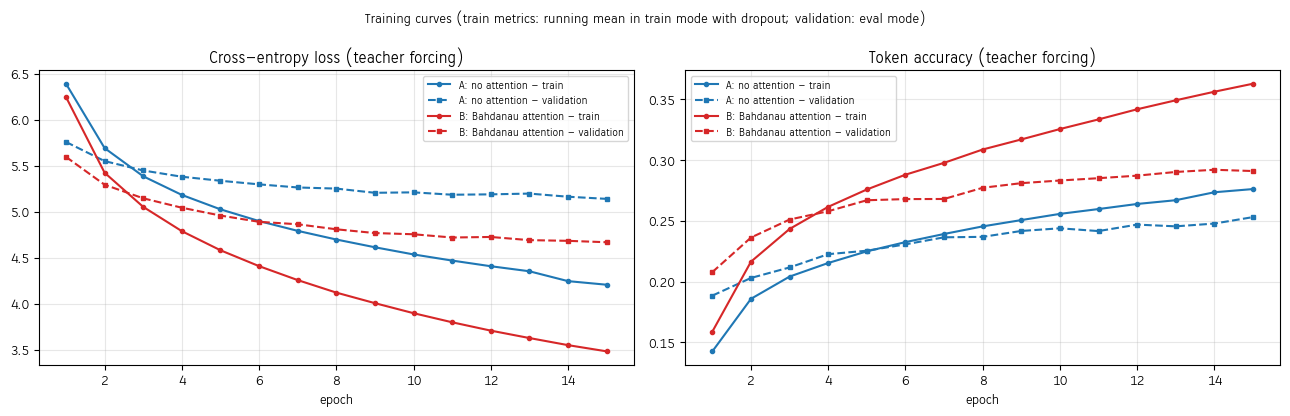

,Metric,Model A (no attention),Model B (attention)
0,Parameters,"16,966,432","17,818,912"
1,Best epoch (val loss) / epochs run,15 / 15,15 / 15
2,Training time (s),600,817
3,Final-epoch train loss / acc,4.2071 / 0.2762,3.4832 / 0.3629
4,Best val loss / acc @best epoch,5.1401 / 0.2531,4.6688 / 0.2910
5,TEST teacher-forced loss / ppl / acc,5.1085 / 165.4 / 0.2496,4.6478 / 104.4 / 0.2915
6,TEST BLEU (greedy),0.40,2.12
7,TEST chrF (greedy),4.71,11.69
8,TEST exact-match rate,0.0000,0.0000
9,Hyp/ref length ratio (all test),1.039,1.056


Paired bootstrap (200 resamples) of BLEU(B) - BLEU(A): mean +1.72, 95% CI [+1.49, +1.91], share of resamples with B <= A: 0.000


In [20]:
def plot_training_curves(hA, hB, path):
    fig, axs = plt.subplots(1, 2, figsize=(13, 4.2))
    for ax, (k, ttl) in zip(axs, [("loss", "Cross-entropy loss (teacher forcing)"), ("acc", "Token accuracy (teacher forcing)")]):
        for h, lab, col in [(hA, "A: no attention", "tab:blue"), (hB, "B: Bahdanau attention", "tab:red")]:
            ep = np.arange(1, len(h["train_" + k]) + 1)
            ax.plot(ep, h["train_" + k], "-o", color=col, ms=3, label=f"{lab} - train")
            ax.plot(ep, h["val_" + k], "--s", color=col, ms=3, label=f"{lab} - validation")
        ax.set_xlabel("epoch"); ax.set_title(ttl); ax.grid(alpha=.3); ax.legend(fontsize=8)
    fig.suptitle("Training curves (train metrics: running mean in train mode with dropout; validation: eval mode)", fontsize=10)
    fig.tight_layout(); fig.savefig(path, dpi=150); plt.show()

plot_training_curves(histA, histB, os.path.join(CFG["out_dir"], "training_curves.png"))

def paired_bootstrap(hA, hB, refs, n, seed):
    rs = np.random.RandomState(seed); N = len(refs); d = []
    for _ in range(n):
        ix = rs.randint(0, N, N)
        r = [refs[i] for i in ix]
        a = bleu_corpus.corpus_score([hA[i] for i in ix], [r]).score; b = bleu_corpus.corpus_score([hB[i] for i in ix], [r]).score
        d.append(b - a)
    d = np.array(d); return d.mean(), np.percentile(d, 2.5), np.percentile(d, 97.5), float((d <= 0).mean())

boot = paired_bootstrap(resA["hyps"], resB["hyps"], resA["refs"], CFG["n_bootstrap"], CFG["seed"])
summary = pd.DataFrame([
    ["Parameters", f'{metaA["params"]:,}', f'{metaB["params"]:,}'],
    ["Best epoch (val loss) / epochs run", f'{metaA["best_epoch"]} / {metaA["epochs_run"]}', f'{metaB["best_epoch"]} / {metaB["epochs_run"]}'],
    ["Training time (s)", f'{metaA["train_seconds"]:.0f}', f'{metaB["train_seconds"]:.0f}'],
    ["Final-epoch train loss / acc", f'{histA["train_loss"][-1]:.4f} / {histA["train_acc"][-1]:.4f}', f'{histB["train_loss"][-1]:.4f} / {histB["train_acc"][-1]:.4f}'],
    ["Best val loss / acc @best epoch", f'{min(histA["val_loss"]):.4f} / {histA["val_acc"][int(np.argmin(histA["val_loss"]))]:.4f}', f'{min(histB["val_loss"]):.4f} / {histB["val_acc"][int(np.argmin(histB["val_loss"]))]:.4f}'],
    ["TEST teacher-forced loss / ppl / acc", f'{resA["tf"]["loss"]:.4f} / {resA["tf"]["ppl"]:.1f} / {resA["tf"]["acc"]:.4f}', f'{resB["tf"]["loss"]:.4f} / {resB["tf"]["ppl"]:.1f} / {resB["tf"]["acc"]:.4f}'],
    ["TEST BLEU (greedy)", f'{resA["bleu"]:.2f}', f'{resB["bleu"]:.2f}'],
    ["TEST chrF (greedy)", f'{resA["chrf"]:.2f}', f'{resB["chrf"]:.2f}'],
    ["TEST exact-match rate", f'{resA["exact"]:.4f}', f'{resB["exact"]:.4f}'],
    ["Hyp/ref length ratio (all test)", f'{sum(len(r["hyp_tok"]) for r in resA["trans"])/sum(x["tgt_n"] for x in test_items):.3f}',
                                         f'{sum(len(r["hyp_tok"]) for r in resB["trans"])/sum(x["tgt_n"] for x in test_items):.3f}'],
    ["% hypotheses that ended with <EOS>", f'{100*np.mean([r["ended"] for r in resA["trans"]]):.1f}', f'{100*np.mean([r["ended"] for r in resB["trans"]]):.1f}'],
], columns=["Metric", "Model A (no attention)", "Model B (attention)"])
display(summary)
print(f"Paired bootstrap ({CFG['n_bootstrap']} resamples) of BLEU(B) - BLEU(A): mean {boot[0]:+.2f}, 95% CI [{boot[1]:+.2f}, {boot[2]:+.2f}], "
      f"share of resamples with B <= A: {boot[3]:.3f}")
summary.to_csv(os.path.join(CFG["out_dir"], "model_comparison.csv"), index=False)

### Part 5 discussion – effect of adding attention

**(i) Validation loss and accuracy.**
Attention improved both. Best validation loss fell from 5.1401 (Model A) to 4.6688 (Model B), a drop of 0.47, and validation token accuracy rose from 0.2531 to 0.2910 (+3.8 points). Both models reached their best validation loss at epoch 15, the last epoch, so neither had converged and early stopping never triggered. On the test set, teacher-forced loss went from 5.1085 to 4.6478, perplexity from 165.4 to 104.4, and accuracy from 0.2496 to 0.2915.

**(ii) Do BLEU and chrF agree?**
Yes, both favour the attention model. BLEU rose from 0.40 to 2.12 (+1.72) and chrF from 4.71 to 11.69 (+6.98). The absolute scores are still low and exact-match is 0.0000 for both models, so neither translates well. chrF shows the difference more clearly because BLEU is close to zero for both. The length ratio (1.039 vs 1.056) and the share of outputs ending with <EOS> (93.2% vs 92.7%) are almost identical, so attention did not change how the models decide when to stop.

**(iii) Is the BLEU difference larger than the bootstrap interval?**
The paired bootstrap (200 resamples) gives a mean BLEU(B) − BLEU(A) of +1.72 with a 95%. The interval lies entirely above zero, so the improvement is not explained by test-sentence sampling noise. This interval covers only the choice of test sentences. It does not cover training randomness, and I trained one model per setting with one seed, so I cannot say how much the gap would vary across seeds.

**(iv) Cost of attention.**
Parameters increased from 16,966,432 to 17,818,912 (+852,480, about +5%), because attention adds only the three projection layers and a wider decoder input; most parameters are in the embedding and output layers. Training time rose from 600 s to 817 s (+217 s, about +36%), because the attention scores are recomputed at every decoder step. The accuracy gain was large relative to the parameter cost.

**(v) Over-fitting.**
There is no clear over-fitting yet: validation loss was still decreasing at epoch 15 for both models. The train–validation gap is larger for the attention model. At epoch 15, Model A had train loss 4.2071 vs validation 5.1401 (gap 0.93, accuracy 0.2762 vs 0.2531), and Model B had 3.4832 vs 4.6688 (gap 1.19, accuracy 0.3629 vs 0.2910). Attention lets the decoder fit the training data more strongly, and part of that does not transfer to validation. Note that training metrics are running averages with dropout on, so they are not directly comparable to validation. Both models were still improving when training stopped, so longer training could change these conclusions.

## 6 · Part 6 – Visualising what the model attends to
For selected test translations the attention matrix `α_{t,i}` is plotted with **x-axis = English tokens** (including `<SOS>`/`<EOS>`) and **y-axis = generated Hindi tokens** (the last row is the generated `<EOS>`).
Selection (deterministic, seeded): translations of the attention model with a high sentence-level chrF among short/medium sentences, plus one longer sentence. Error cases are visualised in §7.

Besides the pictures, **quantitative attention diagnostics** are computed over the whole test set (per length group):
* `entropy_norm` – mean normalised entropy of each step's distribution (0 = one source word, 1 = uniform);
* `max_w` – mean largest weight per step;
* `n_>0.2` – mean number of source positions with weight above 0.2 (multi-word attention);
* `mono_frac` – share of steps whose arg-max source position is ≥ the previous step's (a crude measure of *sequential* movement; English→Hindi has systematic **reordering** (SVO→SOV), so low values are expected and not automatically bad);
* `mass_<EOS>` / `mass_<SOS>` – attention on the sentence-boundary tokens (often used by the model as a "no-op"/sink).

Selected test indices for heat-maps: [112, 1464, 570, 2367]


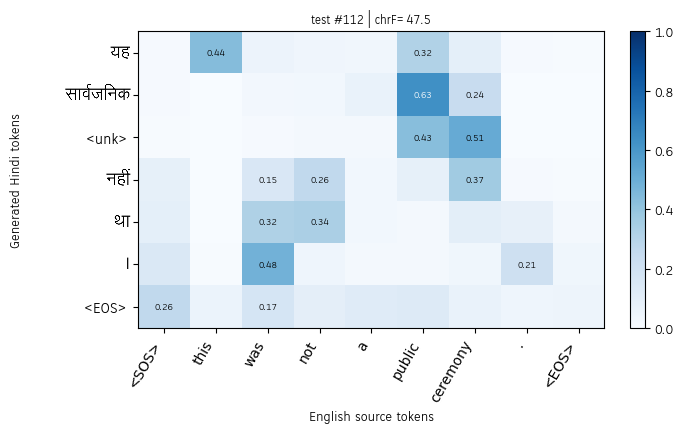

EN : this was not a public ceremony .
REF: यह कोई सार्वजनिक समारोह नहीं था ।
A  : यह एक <unk> <unk> है ।
B  : यह सार्वजनिक <unk> नहीं था ।


,,this,was,not,a,public,ceremony,.,
यह,,0.44,0.06,,,0.32,0.09,,
सार्वजनिक,,,,,0.07,0.63,0.24,,
,,,,,,0.43,0.51,,
नहीं,0.09,,0.15,0.26,,0.09,0.37,,
था,0.09,,0.32,0.34,,,0.10,0.08,
।,0.15,,0.48,,,,,0.21,
,0.26,0.06,0.17,0.09,0.12,0.13,0.07,,


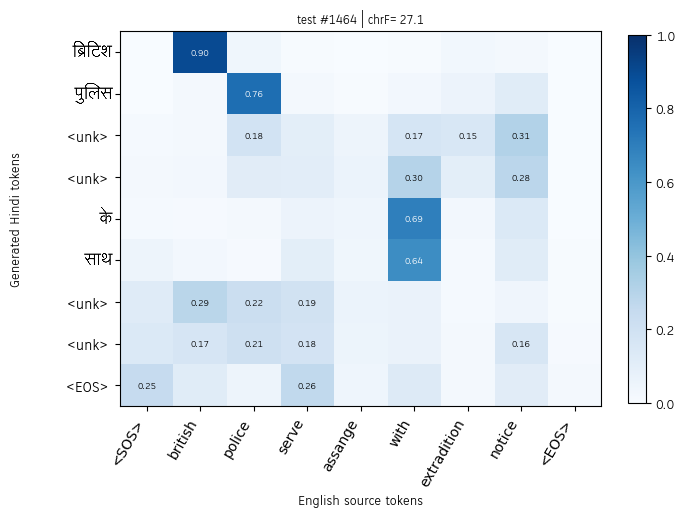

EN : british police serve assange with extradition notice
REF: ब्रिटिश पुलिस ने असांजे को प्रत्यर्पण नोटिस भेजी
A  : <unk> <unk> <unk> <unk> <unk> <unk>
B  : ब्रिटिश पुलिस <unk> <unk> के साथ <unk> <unk>


,,british,police,serve,assange,with,extradition,notice,
ब्रिटिश,,0.90,,,,,,,
पुलिस,,,0.76,,,,0.06,0.11,
,,,0.18,0.10,,0.17,0.15,0.31,
,,,0.11,0.10,0.06,0.30,0.10,0.28,
के,,,,0.06,,0.69,,0.14,
साथ,0.05,,,0.10,,0.64,,0.12,
,0.12,0.29,0.22,0.19,0.06,0.07,,,
,0.14,0.17,0.21,0.18,0.05,0.06,,0.16,
,0.25,0.11,,0.26,,0.13,,0.11,


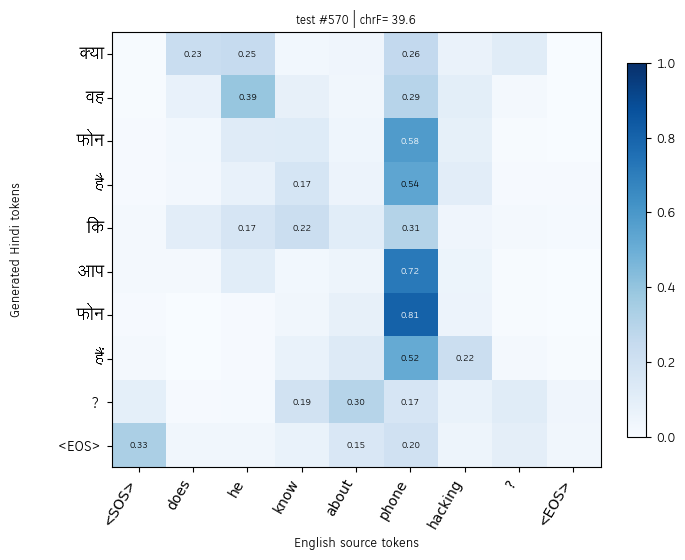

EN : does he know about phone hacking ?
REF: क्या वह फोन हैकिंग के बारे में जानते थे ?
A  : क्या आप अपने <unk> को <unk> कर सकते हैं ?
B  : क्या वह फोन है कि आप फोन हैं ?


,,does,he,know,about,phone,hacking,?,
क्या,,0.23,0.25,,,0.26,0.06,0.11,
वह,,0.07,0.39,0.08,,0.29,0.10,,
फोन,,,0.12,0.12,,0.58,0.08,,
है,,,0.08,0.17,0.06,0.54,0.10,,
कि,,0.10,0.17,0.22,0.11,0.31,,,
आप,,,0.11,,,0.72,0.05,,
फोन,,,,,0.08,0.81,0.06,,
हैं,,,,0.07,0.13,0.52,0.22,,
?,0.09,,,0.19,0.30,0.17,0.07,0.11,
,0.33,,,0.07,0.15,0.20,,0.10,


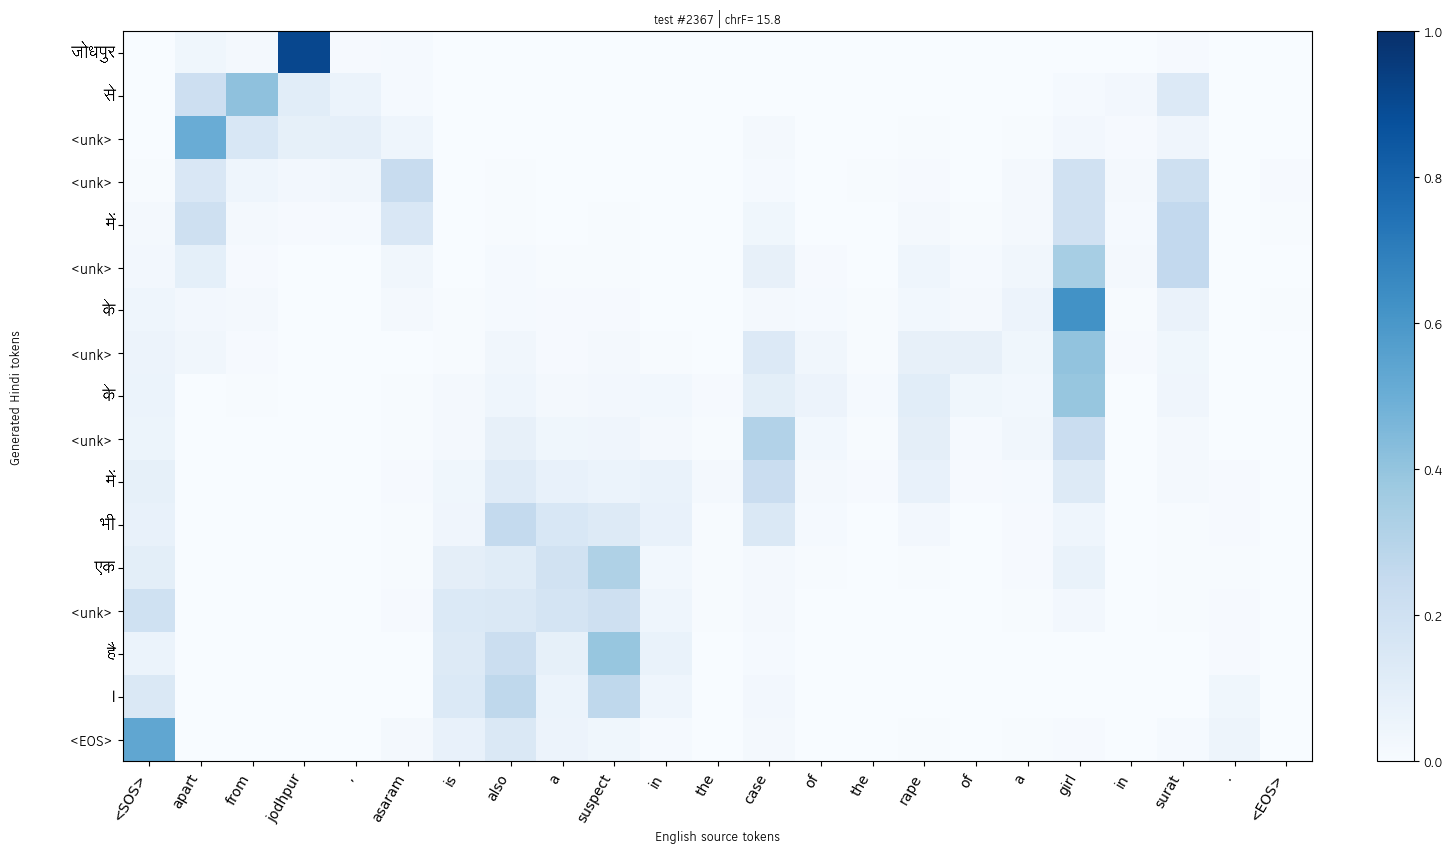

EN : apart from jodhpur , asaram is also a suspect in the case of the rape of a girl in surat .
REF: जोधपुर के अलावा आसाराम सूरत की एक लड़की से दुष्कर्म के मामले में भी आरोपी हैं ।
A  : <unk> के <unk> में <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> ।
B  : जोधपुर से <unk> <unk> में <unk> के <unk> के <unk> में भी एक <unk> है ।


,,apart,from,jodhpur,",",asaram,is,also,a,suspect,in,the,case,of,the,rape,of,a,girl,in,surat,.,
जोधपुर,,,,0.91,,,,,,,,,,,,,,,,,,,
से,,0.21,0.41,0.11,0.06,,,,,,,,,,,,,,,,0.14,,
,,0.50,0.16,0.08,0.09,,,,,,,,,,,,,,,,,,
,,0.15,,,,0.24,,,,,,,,,,,,,0.20,,0.21,,
में,,0.21,,,,0.15,,,,,,,,,,,,,0.20,,0.26,,
,,0.09,,,,,,,,,,,0.08,,,,,,0.34,,0.26,,
के,,,,,,,,,,,,,,,,,,0.06,0.62,,0.07,,
,0.06,,,,,,,,,,,,0.13,,,0.08,0.08,,0.40,,,,
के,0.06,,,,,,,,,,,,0.10,0.05,,0.11,,,0.39,,,,
,0.05,,,,,,,0.08,,,,,0.31,,,0.10,,,0.23,,,,


In [21]:
def plot_attention(ax, src_toks, hyp_toks, alpha, title=None, annotate=True, vmax=1.0):
    im = ax.imshow(alpha, aspect="auto", cmap="Blues", vmin=0.0, vmax=vmax)
    ax.set_xticks(range(len(src_toks))); ax.set_yticks(range(len(hyp_toks)))
    ax.set_xticklabels(src_toks, rotation=60, ha="right")
    ax.set_yticklabels([("" if (RAQM_OK and DEVA_RE_PLOT.search(t)) else t) for t in hyp_toks])
    for lb in ax.get_xticklabels(): lb.set_fontproperties(LATIN_FP)
    for lb in ax.get_yticklabels(): lb.set_fontproperties(HINDI_FP)
    if RAQM_OK:
        w_pts = 0.0
        for r_, t in enumerate(hyp_toks):
            if DEVA_RE_PLOT.search(t): w_pts = max(w_pts, add_shaped_ytick(ax, t, r_))
        ax.yaxis.labelpad = w_pts + 8
    if annotate and alpha.size <= 18 * 18:
        for r in range(alpha.shape[0]):
            for c in range(alpha.shape[1]):
                if alpha[r, c] >= 0.15:
                    ax.text(c, r, f"{alpha[r, c]:.2f}", ha="center", va="center", fontsize=7, color="white" if alpha[r, c] > .55 else "black")
    ax.set_xlabel("English source tokens"); ax.set_ylabel("Generated Hindi tokens")
    if title: ax.set_title(title, fontsize=9)
    return im

def attention_html(src_toks, hyp_toks, alpha, title=""):
    """Browser-rendered heat-map (uses the browser's text shaping for Devanagari)."""
    h = [f"<div style='margin:8px 0;font-family:\"Noto Sans Devanagari\",\"Lohit Devanagari\",Mangal,sans-serif'><b>{title}</b>",
         "<table style='border-collapse:collapse;font-size:13px'><tr><th></th>" + "".join(f"<th style='padding:2px 6px;writing-mode:vertical-rl;transform:rotate(180deg)'>{t}</th>" for t in src_toks) + "</tr>"]
    for r, ht in enumerate(hyp_toks):
        h.append(f"<tr><td style='padding:2px 8px;text-align:right'>{ht}</td>" +
                 "".join(f"<td style='width:34px;height:22px;text-align:center;font-size:10px;background:rgba(31,119,180,{min(float(a),1):.3f});color:{'#fff' if a>.55 else '#000'}'>{a:.2f}</td>" if a >= .05 else
                         f"<td style='width:34px;height:22px;background:rgba(31,119,180,{min(float(a),1):.3f})'></td>" for a in alpha[r]) + "</tr>")
    h.append("</table></div>"); return "".join(h)

def attn_example(res, i):
    x = test_items[i]; r = res["trans"][i]
    src = ["<SOS>"] + x["src_tok"] + ["<EOS>"]
    hyp = r["hyp_tok"] + (["<EOS>"] if r["ended"] else [])
    a = r["attn"][:len(hyp)]
    return src, hyp, a

# ---- choose examples (seeded, deterministic) ----
rs = random.Random(CFG["seed"] + 1)
cand_good = [i for i in range(len(test_items)) if 4 <= test_items[i]["src_n"] <= 12 and resB["sent_chrf"][i] >= np.percentile(resB["sent_chrf"], 70) and resB["trans"][i]["ended"]]
cand_long = [i for i in range(len(test_items)) if test_items[i]["src_n"] >= 16 and test_items[i]["src_n"] <= 28 and resB["trans"][i]["ended"]]
n_good = max(CFG["n_heatmaps"] - 1, 1)
sel = rs.sample(cand_good, min(n_good, len(cand_good))) + (rs.sample(cand_long, 1) if cand_long else [])
if not sel: sel = list(range(min(CFG["n_heatmaps"], len(test_items))))   # fallback for tiny/odd data
print("Selected test indices for heat-maps:", sel)

for i in sel:
    src, hyp, a = attn_example(resB, i)
    fig, ax = plt.subplots(figsize=(max(5, 0.55 * len(src) + 2), min(14, max(3.2, 0.42 * len(hyp) + 1.5))))
    im = plot_attention(ax, src, hyp, a, title=f"test #{i} | chrF={resB['sent_chrf'][i]:.1f}")
    fig.colorbar(im, ax=ax, fraction=0.035); fig.tight_layout()
    fig.savefig(os.path.join(CFG["out_dir"], f"heatmap_test_{i}.png"), dpi=150); plt.show()
    print("EN :", " ".join(test_items[i]["src_tok"])); print("REF:", resB["refs"][i]); print("A  :", resA["hyps"][i]); print("B  :", resB["hyps"][i])
    display(HTML(attention_html(src, hyp, a, title=f"(HTML version) test #{i}")))

In [17]:
# ---- quantitative attention diagnostics over the whole test set ----
def attention_stats(res):
    rows = []
    for i, r in enumerate(res["trans"]):
        a = r["attn"]
        if a is None or a.shape[0] == 0: continue
        S = a.shape[1]; eps = 1e-12
        ent = -(a * np.log(a + eps)).sum(1) / max(math.log(S), eps) if S > 1 else np.zeros(a.shape[0])
        am = a.argmax(1); body = am[:-1] if r["ended"] and len(am) > 1 else am
        mono = float(np.mean(body[1:] >= body[:-1])) if len(body) > 1 else np.nan
        rows.append(dict(idx=i, src_n=test_items[i]["src_n"], bucket=bucket_name(bucket_of(test_items[i]["src_n"])),
                         entropy_norm=float(ent.mean()), max_w=float(a.max(1).mean()), n_gt_02=float((a > 0.2).sum(1).mean()),
                         mono_frac=mono, mass_eos=float(a[:, -1].mean()), mass_sos=float(a[:, 0].mean())))
    return pd.DataFrame(rows)

att_df = attention_stats(resB)
att_tab = att_df.groupby("bucket").agg(n=("idx", "count"), entropy_norm=("entropy_norm", "mean"), max_w=("max_w", "mean"),
                                         **{"n_>0.2": ("n_gt_02", "mean")}, mono_frac=("mono_frac", "mean"),
                                         mass_EOS=("mass_eos", "mean"), mass_SOS=("mass_sos", "mean")).reindex(BUCKET_NAMES)
overall = att_df[["entropy_norm", "max_w", "n_gt_02", "mono_frac", "mass_eos", "mass_sos"]].mean()
print("Attention diagnostics of Model B over the test set (per English-length group):")
display(att_tab.round(3))
print("Overall means:", overall.round(3).to_dict())
att_tab.to_csv(os.path.join(CFG["out_dir"], "attention_diagnostics.csv"))
# does the model attend more sharply when it translates better?
if len(att_df) > 5:
    cc = np.corrcoef(att_df["max_w"], [resB["sent_chrf"][i] for i in att_df.idx])[0, 1]
    ce = np.corrcoef(att_df["entropy_norm"], [resB["sent_chrf"][i] for i in att_df.idx])[0, 1]
    print(f"Pearson r(sentence chrF, mean max attention weight) = {cc:+.3f};  r(sentence chrF, normalised entropy) = {ce:+.3f}")

Attention diagnostics of Model B over the test set (per English-length group):


,n,entropy_norm,max_w,n_>0.2,mono_frac,mass_EOS,mass_SOS
bucket,,,,,,,
1-5,10,0.613,0.544,1.718,0.747,0.019,0.138
6-10,256,0.651,0.444,1.618,0.759,0.015,0.097
11-15,455,0.672,0.379,1.398,0.751,0.008,0.076
16+,1745,0.687,0.295,0.939,0.786,0.003,0.052


Overall means: {'entropy_norm': 0.68, 'max_w': 0.327, 'n_gt_02': 1.097, 'mono_frac': 0.777, 'mass_eos': 0.005, 'mass_sos': 0.061}
Pearson r(sentence chrF, mean max attention weight) = +0.356;  r(sentence chrF, normalised entropy) = -0.364


### Part 6: Discussion

**1. High-attention words:** Attention on `<EOS>` is very low (0.005), while `<SOS>` gets 0.061. Attention often focuses on content words. For example, test #1464: `ब्रिटिश` → `british` (0.90).

**2. Relevant source words:** Some meaningful correspondences appear:
- Test #1464: `ब्रिटिश` → `british` (0.90).
- Test #1464: `पुलिस` → `police` (0.76).
- Test #570: `फोन` → `phone` (0.81).

However, BLEU is only 2.12, so attention is not a reliable alignment.

**3. Sequential?** `mono_frac` = 0.777, meaning attention mostly stays at or moves forward through source positions. In test #112, the final Hindi verb `था` attends to English `was` (0.32), showing possible SVO-to-SOV reordering.

**4. Several source words:** Short sentences often attend to around two positions (`n_>0.2` = 1.72). For 16+ tokens, it falls to 0.94. Test #1464 shows `साथ` attending to `with` (0.64). A clear postposition example was not verified.

**5. Wrong or diffuse attention:** Attention becomes more diffuse with sentence length (maximum weight 0.544 → 0.295; entropy 0.613 → 0.687). Test #2367 shows diffuse attention and several `<unk>` tokens. Test #570 shows sharp attention to `phone`, but the generated sentence is still incorrect.

*Attention weights are not guaranteed to represent word alignment or explain the model's decisions.*

## 7 · Part 7 – Attention-based error analysis
**Case selection (seeded, reproducible):** test sentences with 3–25 source tokens where the attention model's sentence-level chrF is below 50 and the translation differs from the reference (so the heat-maps stay readable). If fewer than `n_error_cases` such sentences exist, the lowest-scoring ones are used. Threshold and size are configurable.

For each case we print English, reference, baseline output, attention output and show the heat-map. The **automatic flags** are heuristics only (they propose candidate error types; they are *not* the final classification):

| flag | rule |
|---|---|
| `OOV` | the English source contains `<unk>` after vocabulary lookup (or the output contains `<unk>`) |
| `missing_words?` | hypothesis shorter than 70 % of the reference length |
| `extra_words?` | hypothesis longer than 130 % of the reference length |
| `repetition` | a token bigram repeats within the hypothesis |
| `word_order?` | ≥ 80 % token-set overlap with the reference but different order |
| `long_distance?` | source has ≥ 16 tokens |
| `diffuse_attention?` | mean normalised attention entropy > 0.7 |
| `attn_on_boundary?` | average attention on `<EOS>` + `<SOS>` > 0.5 |
| `no_EOS` | decoding hit `max_decode_len` without `<EOS>` |



1624 test sentences met the error criterion; analysing 8 (>=5 required): [342, 561, 721, 1218, 1315, 1686, 1738, 2182]
test #342  | auto-flags: ['OOV', 'extra_words?', 'repetition', 'diffuse_attention?']
EN : to test this researchers did two experiments .
REF: इसके लिए रिसर्चर्स ने दो प्रयोग किए ।
A  : इस प्रकार के <unk> में <unk> की गई है ।    (chrF 9.6)
B  : इस तरह से इस तरह से दो <unk> को <unk> करना ।    (chrF 11.0)


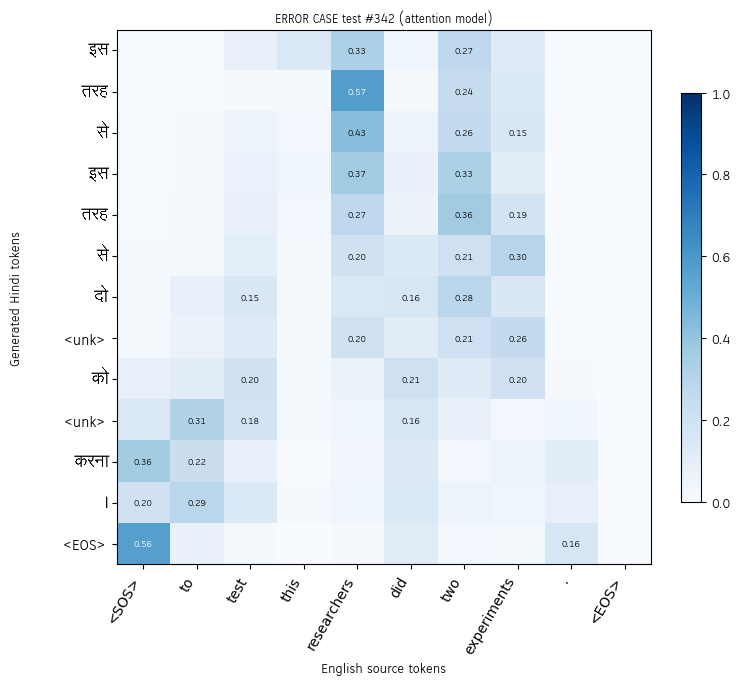

test #561  | auto-flags: ['OOV', 'repetition', 'long_distance?']
EN : the camp chief and commissioner of state training , vipin kumar , is offering special assistance .
REF: शिविर प्रधान विपिन कुमार राज्य प्रशिक्षण आयुक्त अपना विशेष सहयोग दे रहे हैं ।
A  : <unk> , <unk> , <unk> , <unk> , <unk> , <unk> , <unk> , <unk> , <unk> , <unk> , <unk> , <unk> , <unk> , <unk> , <unk> , <unk> , <unk> , <unk> , <unk> , <unk> ।    (chrF 0.2)
B  : राज्य प्रशिक्षण , <unk> कुमार , आयुक्त , <unk> <unk> <unk> <unk> <unk> है ।    (chrF 29.6)


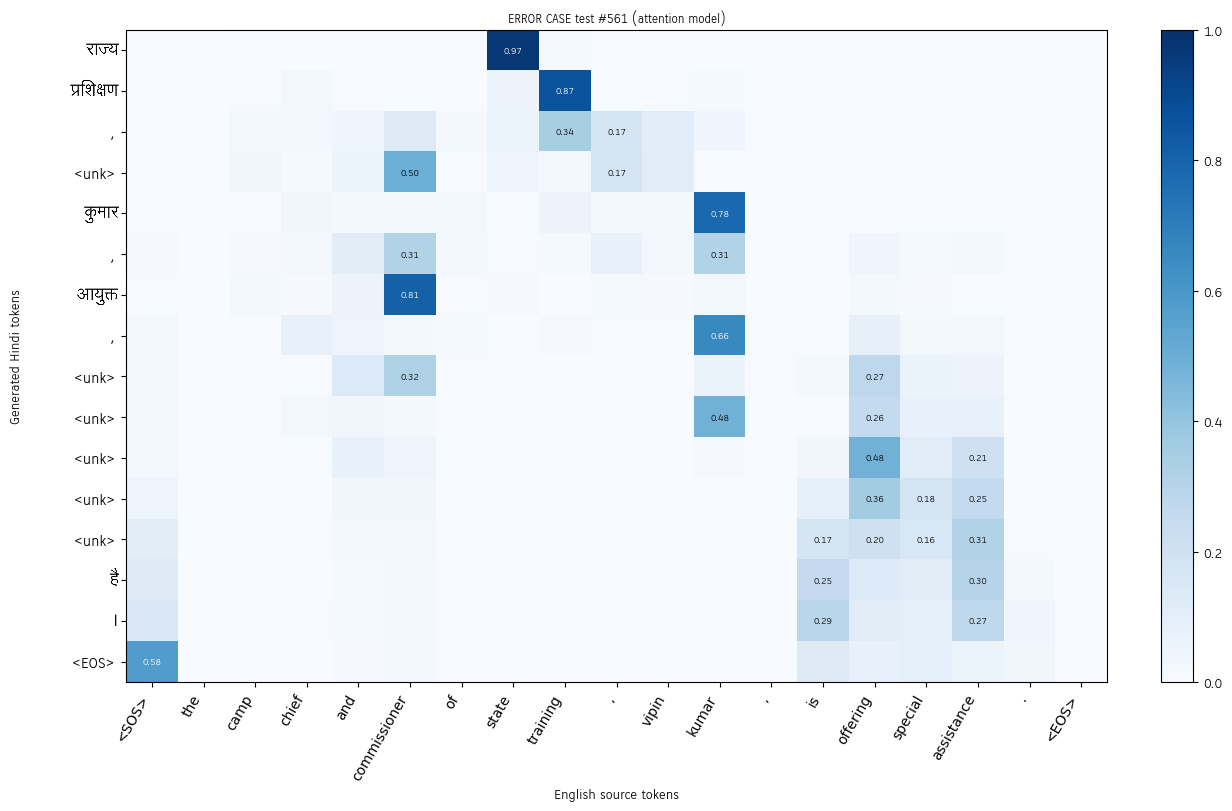

test #721  | auto-flags: ['OOV', 'missing_words?']
EN : german law is about assigning it at birth .
REF: जर्मनी का कानून इसे जन्म के समय निर्दिष्ट करने से सम्बन्धित है ।
A  : <unk> <unk> <unk> <unk> <unk> <unk> है ।    (chrF 2.1)
B  : जर्मन कानून यह <unk> <unk> है ।    (chrF 13.6)


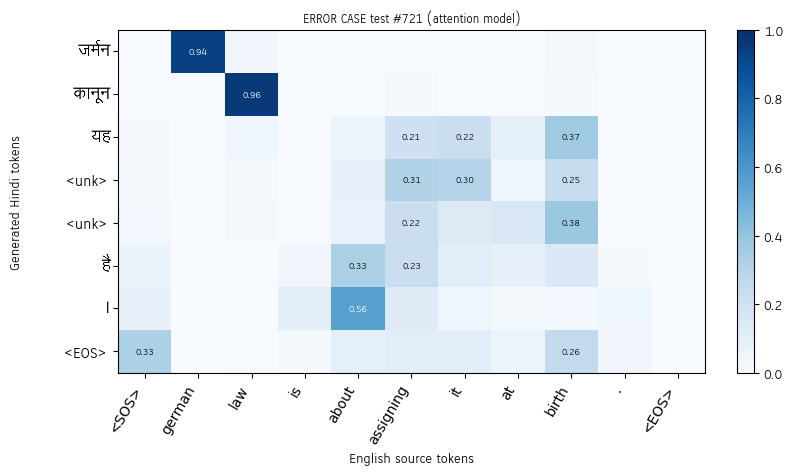

test #1218  | auto-flags: ['OOV', 'repetition', 'long_distance?']
EN : they were unable to visit two sites because of security concerns , the inspectors said .
REF: निरीक्षकों ने कहा कि वे सुरक्षा कारणों से दो केन्द्रों पर जाने में सक्षम नहीं थे ।
A  : उन्होंने कहा कि भारत के सभी क्षेत्रों में <unk> के लिए <unk> के लिए <unk> की गई है ।    (chrF 22.2)
B  : <unk> ने कहा कि सुरक्षा के लिए <unk> <unk> के कारण <unk> ने कहा ।    (chrF 22.3)


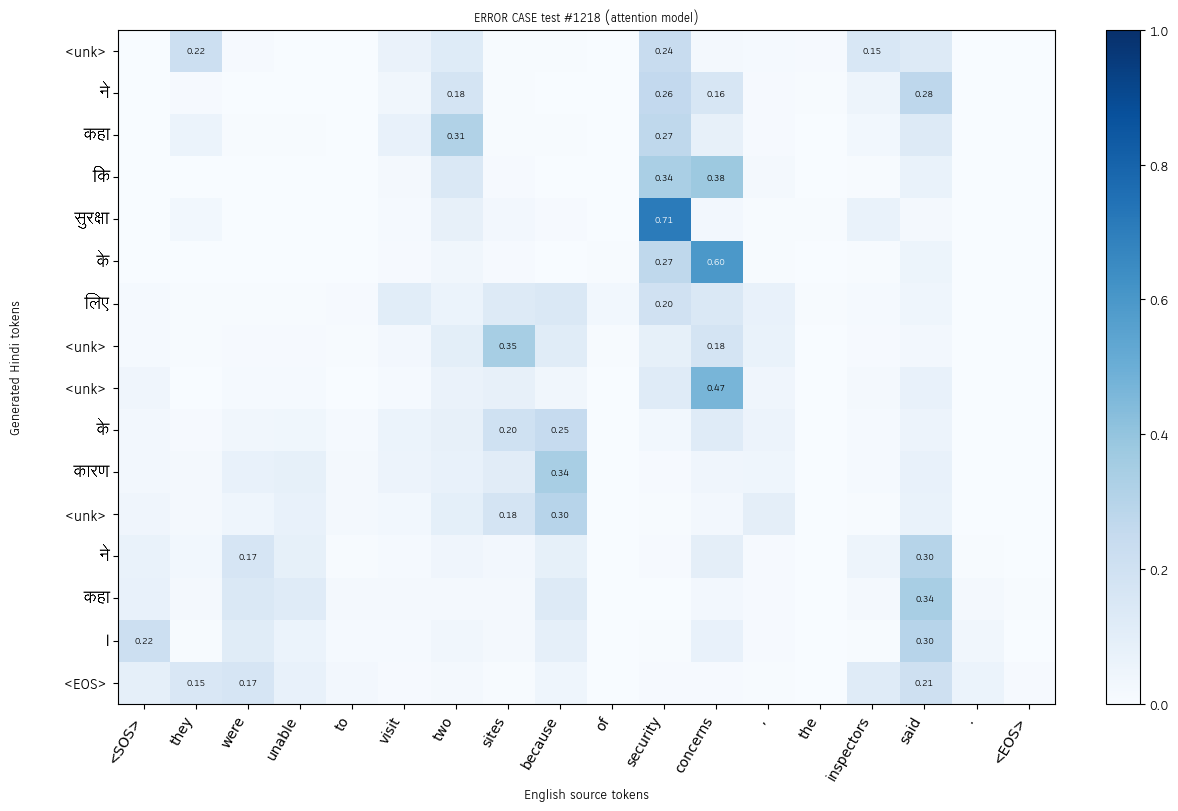

test #1315  | auto-flags: ['OOV', 'extra_words?', 'repetition', 'long_distance?', 'diffuse_attention?']
EN : the station shos have been ordered to set up a special investigation team ( sit ) to investigate the case .
REF: थाना एसएचओ को मामलों की तफ्तीश के लिए स्पेशल इंवेस्टीगेशन टीम ( एसआइटी ) का गठन करने के निर्देश दिए हैं ।
A  : <unk> <unk> के लिए <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> है ।    (chrF 3.6)
B  : <unk> <unk> के लिए एक <unk> <unk> <unk> ( <unk> ) के लिए <unk> <unk> के लिए <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk>    (chrF 5.6)


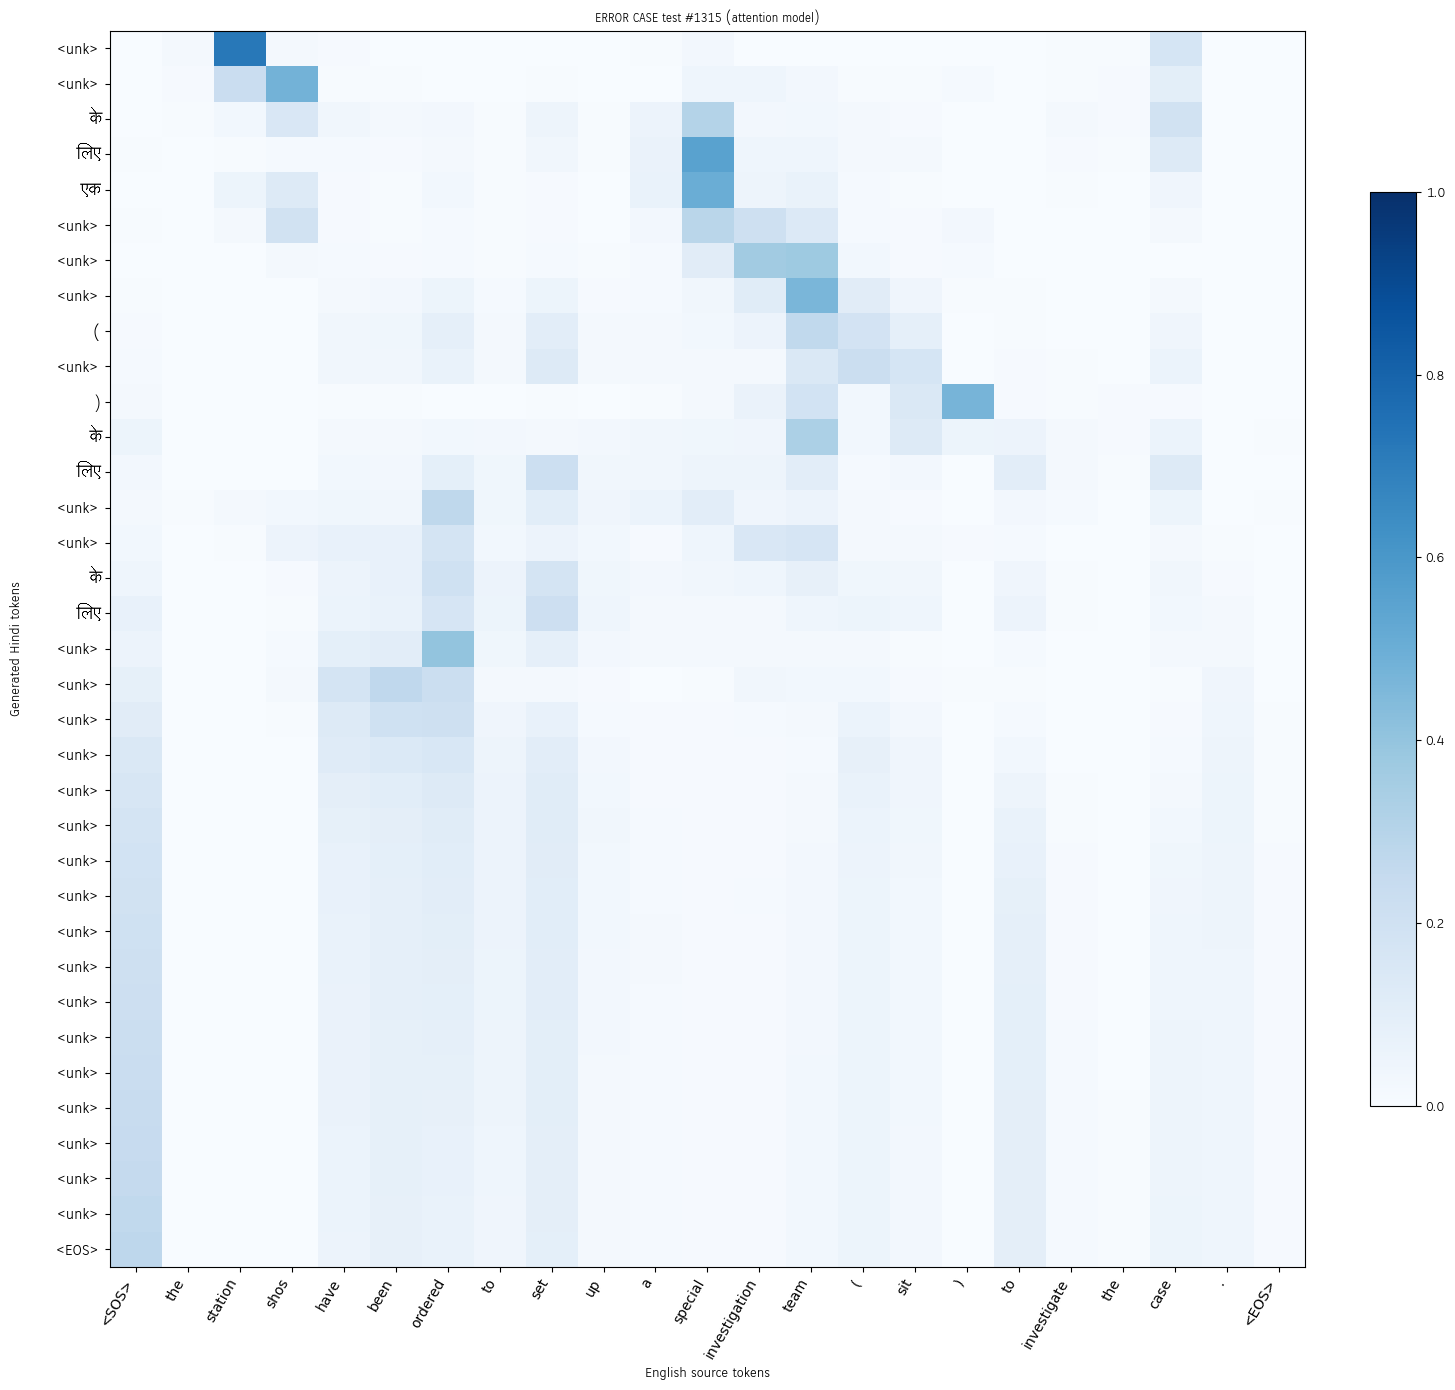

test #1686  | auto-flags: ['OOV', 'repetition', 'diffuse_attention?']
EN : only wealth gained with self - respect is long lasting .
REF: वही धन - संपदा टिकाऊ होती है जिसके साथ सम्मान जुड़ा हुआ हो ।
A  : <unk> के लिए <unk> <unk> के लिए <unk> <unk> <unk> ।    (chrF 2.6)
B  : केवल <unk> के साथ ही साथ ही बहुत अधिक महत्वपूर्ण है ।    (chrF 14.3)


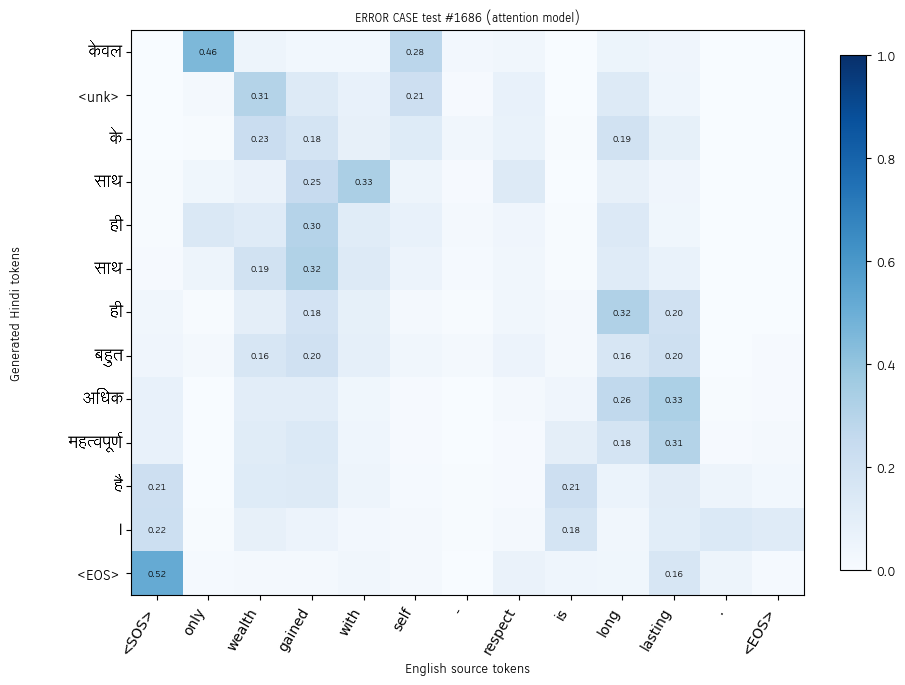

test #1738  | auto-flags: ['OOV', 'extra_words?', 'repetition', 'diffuse_attention?']
EN : the nia wants to find the other suspects in this case by interrogating ahmed .
REF: अहमद से पूछताछ के जरिये एनआइए मामले में अन्य आरोपियों को भी गिरफ्तार करना चाहती है ।
A  : <unk> के <unk> में <unk> के लिए <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> ।    (chrF 3.7)
B  : इस <unk> द्वारा <unk> द्वारा <unk> <unk> द्वारा <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> <unk> ।    (chrF 3.3)


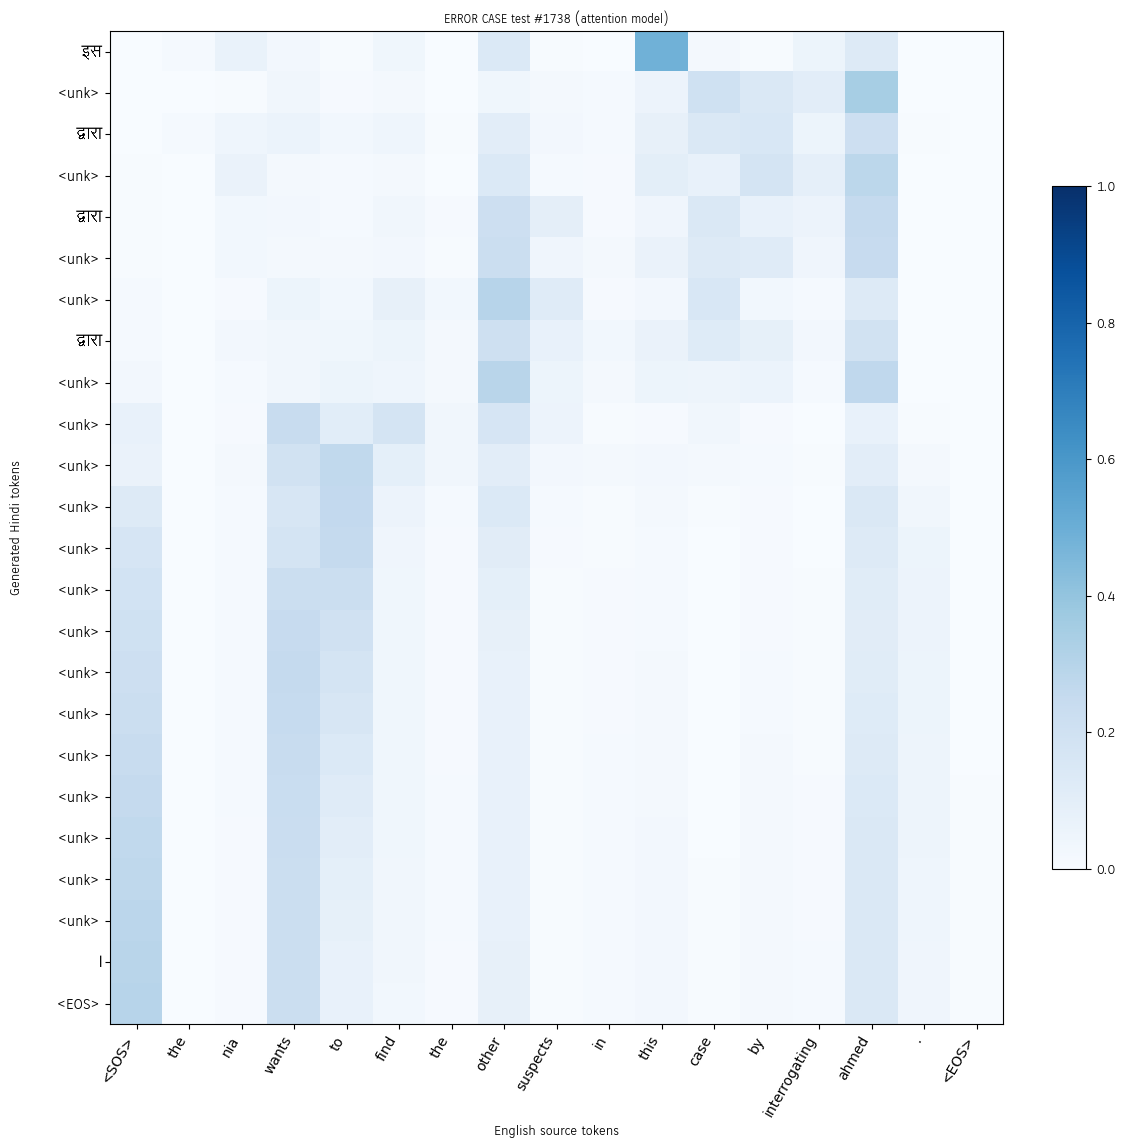

test #2182  | auto-flags: ['OOV', 'repetition', 'diffuse_attention?']
EN : trekking through mud , rivers and jungle to provide free medical care
REF: निःशुल्क चिकित्सा सेवा प्रदान करने के लिए मिट्टी , नदियों और जंगल से होते हुए आगे बढ़ना
A  : <unk> और <unk> के लिए <unk> के लिए <unk> <unk> के लिए <unk> <unk>    (chrF 6.8)
B  : <unk> <unk> और <unk> <unk> को प्रोत्साहन देने के लिए <unk> , <unk> और <unk> <unk>    (chrF 13.8)


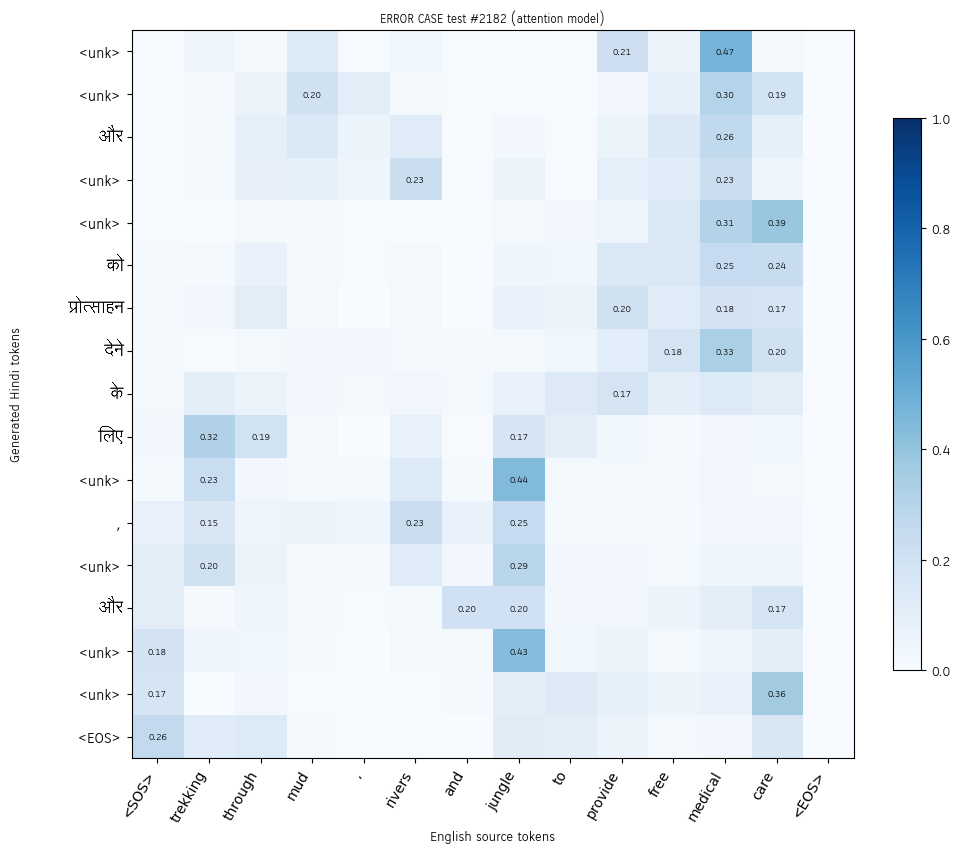

,test_idx,english,reference,baseline_A,attention_B,auto_flags
0,342,to test this researchers did two experiments .,इसके लिए रिसर्चर्स ने दो प्रयोग किए ।,इस प्रकार के <unk> में <unk> की गई है ।,इस तरह से इस तरह से दो <unk> को <unk> करना ।,"OOV, extra_words?, repetition, diffuse_attention?"
1,561,the camp chief and commissioner of state train...,शिविर प्रधान विपिन कुमार राज्य प्रशिक्षण आयुक्...,"<unk> , <unk> , <unk> , <unk> , <unk> , <unk> ...","राज्य प्रशिक्षण , <unk> कुमार , आयुक्त , <unk>...","OOV, repetition, long_distance?"
2,721,german law is about assigning it at birth .,जर्मनी का कानून इसे जन्म के समय निर्दिष्ट करने...,<unk> <unk> <unk> <unk> <unk> <unk> है ।,जर्मन कानून यह <unk> <unk> है ।,"OOV, missing_words?"
3,1218,they were unable to visit two sites because of...,निरीक्षकों ने कहा कि वे सुरक्षा कारणों से दो क...,उन्होंने कहा कि भारत के सभी क्षेत्रों में <unk...,<unk> ने कहा कि सुरक्षा के लिए <unk> <unk> के ...,"OOV, repetition, long_distance?"
4,1315,the station shos have been ordered to set up a...,थाना एसएचओ को मामलों की तफ्तीश के लिए स्पेशल इ...,<unk> <unk> के लिए <unk> <unk> <unk> <unk> <un...,<unk> <unk> के लिए एक <unk> <unk> <unk> ( <unk...,"OOV, extra_words?, repetition, long_distance?,..."
5,1686,only wealth gained with self - respect is long...,वही धन - संपदा टिकाऊ होती है जिसके साथ सम्मान ...,<unk> के लिए <unk> <unk> के लिए <unk> <unk> <u...,केवल <unk> के साथ ही साथ ही बहुत अधिक महत्वपूर...,"OOV, repetition, diffuse_attention?"
6,1738,the nia wants to find the other suspects in th...,अहमद से पूछताछ के जरिये एनआइए मामले में अन्य आ...,<unk> के <unk> में <unk> के लिए <unk> <unk> <u...,इस <unk> द्वारा <unk> द्वारा <unk> <unk> द्वार...,"OOV, extra_words?, repetition, diffuse_attention?"
7,2182,"trekking through mud , rivers and jungle to pr...",निःशुल्क चिकित्सा सेवा प्रदान करने के लिए मिट्...,<unk> और <unk> के लिए <unk> के लिए <unk> <unk>...,<unk> <unk> और <unk> <unk> को प्रोत्साहन देने ...,"OOV, repetition, diffuse_attention?"


Saved: nmt_outputs/error_analysis.csv - fill in the three empty columns (manual_error_type, attention_explains_error, notes).
Auto-flag frequency over the analysed cases: {'OOV': 8, 'extra_words?': 3, 'repetition': 7, 'diffuse_attention?': 5, 'long_distance?': 3, 'missing_words?': 1}


In [22]:
def auto_flags(i, res):
    x = test_items[i]; r = res["trans"][i]; ref, hyp = x["tgt_tok"], r["hyp_tok"]; fl = []
    if UNK_ID in x["src_ids"] or UNK in hyp: fl.append("OOV")
    if len(hyp) < 0.7 * len(ref): fl.append("missing_words?")
    if len(hyp) > 1.3 * len(ref): fl.append("extra_words?")
    bg = list(zip(hyp, hyp[1:]))
    if len(bg) != len(set(bg)): fl.append("repetition")
    if len(ref) and hyp != ref and set(ref) and len(set(ref) & set(hyp)) / len(set(ref) | set(hyp)) >= 0.8: fl.append("word_order?")
    if x["src_n"] >= 16: fl.append("long_distance?")
    a = r["attn"]
    if a is not None and a.shape[0] and a.shape[1] > 1:
        ent = (-(a * np.log(a + 1e-12)).sum(1) / math.log(a.shape[1])).mean()
        if ent > 0.7: fl.append("diffuse_attention?")
        if a[:, -1].mean() + a[:, 0].mean() > 0.5: fl.append("attn_on_boundary?")
    if not r["ended"]: fl.append("no_EOS")
    return fl

rs = random.Random(CFG["seed"] + 2)
bad = [i for i in range(len(test_items)) if 3 <= test_items[i]["src_n"] <= 25 and resB["hyps"][i] != resB["refs"][i] and resB["sent_chrf"][i] < 50]
if len(bad) >= CFG["n_error_cases"]:
    err_idx = sorted(rs.sample(bad, CFG["n_error_cases"]))
else:   # fall back to the lowest-scoring readable sentences
    pool = [i for i in range(len(test_items)) if 3 <= test_items[i]["src_n"] <= 25 and resB["hyps"][i] != resB["refs"][i]]
    err_idx = sorted(sorted(pool, key=lambda i: resB["sent_chrf"][i])[:CFG["n_error_cases"]])
print(f"{len(bad)} test sentences met the error criterion; analysing {len(err_idx)} (>=5 required):", err_idx)
assert len(err_idx) >= 5, "fewer than 5 error cases available - check data/model"

err_rows = []
for i in err_idx:
    fl = auto_flags(i, resB)
    err_rows.append(dict(test_idx=i, english=" ".join(test_items[i]["src_tok"]), reference=resB["refs"][i],
                         baseline_A=resA["hyps"][i], attention_B=resB["hyps"][i], chrF_A=round(resA["sent_chrf"][i], 1),
                         chrF_B=round(resB["sent_chrf"][i], 1), auto_flags=", ".join(fl),
                         manual_error_type="", attention_explains_error="", notes=""))
    print("=" * 110); print(f"test #{i}  | auto-flags: {fl}")
    print("EN :", err_rows[-1]["english"]); print("REF:", err_rows[-1]["reference"])
    print("A  :", err_rows[-1]["baseline_A"], f"   (chrF {resA['sent_chrf'][i]:.1f})")
    print("B  :", err_rows[-1]["attention_B"], f"   (chrF {resB['sent_chrf'][i]:.1f})")
    src, hyp, a = attn_example(resB, i)
    fig, ax = plt.subplots(figsize=(max(5, 0.55 * len(src) + 2), min(14, max(3.2, 0.42 * len(hyp) + 1.5))))
    im = plot_attention(ax, src, hyp, a, title=f"ERROR CASE test #{i} (attention model)")
    fig.colorbar(im, ax=ax, fraction=0.035); fig.tight_layout()
    fig.savefig(os.path.join(CFG["out_dir"], f"error_heatmap_test_{i}.png"), dpi=150); plt.show()

err_df = pd.DataFrame(err_rows)
err_path = os.path.join(CFG["out_dir"], "error_analysis.csv")
err_df.to_csv(err_path, index=False, encoding="utf-8-sig")       # utf-8-sig so Excel shows Devanagari correctly
display(err_df[["test_idx", "english", "reference", "baseline_A", "attention_B", "auto_flags"]])
print("Saved:", err_path, "- fill in the three empty columns (manual_error_type, attention_explains_error, notes).")
flag_counts = Counter(f for r_ in err_rows for f in r_["auto_flags"].split(", ") if f)
print("Auto-flag frequency over the analysed cases:", dict(flag_counts))

### Part 7 – Error analysis (6 incorrect test translations)

Categories: missing word, extra word, incorrect word, incorrect word order, long-distance dependency, unknown/OOV word, incorrect attention focus. (`<unk>×n` = n repeated `<unk>` tokens.)

| test idx | English | reference | baseline A | attention B | error type(s) (manual) | does the heat-map help explain the error? |
|---|---|---|---|---|---|---|
| 342 | to test this researchers did two experiments . | इसके लिए रिसर्चर्स ने दो प्रयोग किए । | इस प्रकार के \<unk\> में \<unk\> की गई है । | इस तरह से इस तरह से दो \<unk\> को \<unk\> करना । | OOV, extra word (repeated "इस तरह से"), missing words (रिसर्चर्स ने), incorrect attention focus | Yes. "तरह" attends to "researchers" (0.57) and "इस" to "researchers"/"two" instead of "to test this"; "दो" correctly attends "two" (0.28). |
| 561 | the camp chief and commissioner of state training , vipin kumar , is offering special assistance . | शिविर प्रधान विपिन कुमार राज्य प्रशिक्षण आयुक्त अपना विशेष सहयोग दे रहे हैं । | \<unk\> , \<unk\> , … (\<unk\>×20) । | राज्य प्रशिक्षण , \<unk\> कुमार , आयुक्त , \<unk\>×5 है । | OOV (vipin), missing words (camp chief; offering special assistance), incorrect word order, incorrect attention focus | Yes. Sharp correct alignments: राज्य←state (0.97), प्रशिक्षण←training (0.87), कुमार←kumar (0.78), आयुक्त←commissioner (0.81). The `<unk>` for "vipin" attends to "commissioner" (0.50), not "vipin". |
| 721 | german law is about assigning it at birth . | जर्मनी का कानून इसे जन्म के समय निर्दिष्ट करने से सम्बन्धित है । | \<unk\>×6 है । | जर्मन कानून यह \<unk\> \<unk\> है । | incorrect word (जर्मन for जर्मनी का), missing words (जन्म के समय), OOV | Partly. जर्मन←german (0.94) and कानून←law (0.96) are sharp and correct. The later words ("यह", `<unk>`) are spread over "assigning/it/birth" (0.2–0.38), which matches the garbled output. |
| 1218 | they were unable to visit two sites because of security concerns , the inspectors said . | निरीक्षकों ने कहा कि वे सुरक्षा कारणों से दो केन्द्रों पर जाने में सक्षम नहीं थे । | उन्होंने कहा कि भारत के सभी क्षेत्रों में \<unk\> के लिए \<unk\> के लिए \<unk\> की गई है । | \<unk\> ने कहा कि सुरक्षा के लिए \<unk\> \<unk\> के कारण \<unk\> ने कहा । | OOV (निरीक्षकों), extra word ("ने कहा" repeated at the end), missing words (they were unable…, सक्षम नहीं), long-distance dependency | Partly. सुरक्षा←security (0.71), के←concerns (0.60), कारण←because (0.34) and the final कहा←said (0.34) are plausible. The first "ने कहा" attends to "visit"/"security" and only weakly to "said" (0.28), so it looks language-model driven. |
| 1686 | only wealth gained with self - respect is long lasting . | वही धन - संपदा टिकाऊ होती है जिसके साथ सम्मान जुड़ा हुआ हो । | \<unk\> के लिए \<unk\> \<unk\> के लिए \<unk\> \<unk\> \<unk\> । | केवल \<unk\> के साथ ही साथ ही बहुत अधिक महत्वपूर्ण है । | incorrect word ("long lasting" → "बहुत अधिक महत्वपूर्ण"), OOV (wealth), missing words (self-respect), extra word (repeated "साथ ही") | Yes. केवल←only (0.46) is right, but most rows peak at only 0.2–0.33 (diffuse), and "के साथ ही साथ ही" is generated while attention is spread over "gained/with". "बहुत अधिक महत्वपूर्ण" attends "long/lasting", so it is a mistranslation, not a focus error. |
| 2182 | trekking through mud , rivers and jungle to provide free medical care | निःशुल्क चिकित्सा सेवा प्रदान करने के लिए मिट्टी , नदियों और जंगल से होते हुए आगे बढ़ना | \<unk\> और \<unk\> के लिए \<unk\> के लिए \<unk\> \<unk\> के लिए \<unk\> \<unk\> | \<unk\> \<unk\> और \<unk\> \<unk\> को प्रोत्साहन देने के लिए \<unk\> , \<unk\> और \<unk\> \<unk\> | OOV (trekking, mud, rivers), incorrect word ("प्रोत्साहन देने" instead of "प्रदान करने"), incorrect word order | No. "प्रोत्साहन देने के लिए" attends to "provide/medical/care" (0.17–0.33), the right source phrase, yet the word chosen is wrong. Attention is plausible but the output is still wrong. |

**How often does the heat-map explain the error?** In 3 of 6 cases (342, 561, 1686) it points to the cause: attention on the wrong word before an error, or diffuse attention before garbled output. In 2 cases (721, 1218) it explains part of the output but not the rest. In 1 case (2182) it is uninformative, since attention is on the right words and the output is still wrong.

**Baseline vs attention.** The baseline mostly outputs long strings of `<unk>` (561, 1315) or a generic sentence unrelated to the source ("उन्होंने कहा कि भारत के सभी क्षेत्रों में…", 1218). Model B copies several correct content words (german law, state training, kumar, security, only), and its sentence-level chrF is higher in 5 of the 6 cases (equal in 1218: 22.2 vs 22.3). So the two models do not make the same mistakes: A's outputs ignore the source, while B's are partly grounded but still incomplete.

**Common cause.** All 6 cases contain unknown words (`<unk>`), which points to the word-level vocabulary as the main limit. Names (vipin), rarer words (trekking, rivers) and Hindi inflections are missing, so the model falls back on `<unk>` and repeated frames like "के लिए" and "ने कहा".

## 8 · Part 8 – Performance by sentence length
Length = number of **English** tokens (excl. `<SOS>/<EOS>`), groups 1–5, 6–10, 11–15, 16+ (configurable). BLEU on very small groups is unstable – the sentence count `n` is printed and annotated in the plot; treat groups with few sentences with caution. The 16+ group is bounded above by `max_len_eval`.

,bucket,n,BLEU_A,chrF_A,tf_acc_A,len_ratio_A,BLEU_B,chrF_B,tf_acc_B,len_ratio_B,dBLEU(B-A),dchrF(B-A),dAcc(B-A)
0,1-5,10,1.167,2.662,0.405,0.581,2.085,7.047,0.429,0.635,0.918,4.385,0.024
1,6-10,256,0.344,5.710,0.313,0.883,3.419,14.581,0.374,0.858,3.075,8.872,0.061
2,11-15,455,0.858,6.407,0.282,1.007,2.371,13.679,0.336,1.011,1.513,7.272,0.054
3,16+,1745,0.313,4.456,0.241,1.052,2.015,11.311,0.281,1.073,1.702,6.855,0.039


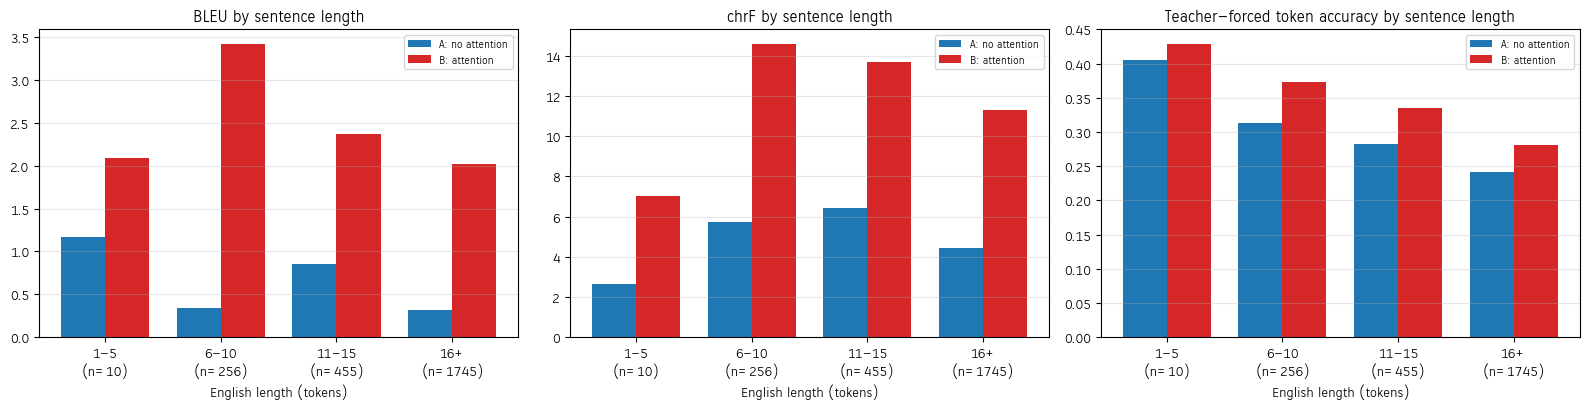

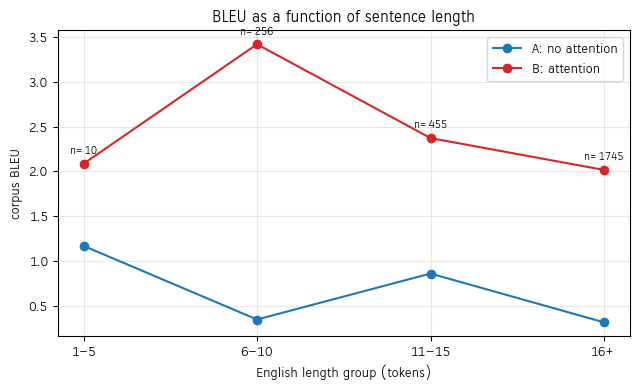

Position-wise recall proxy (Model B):


,bucket,n,recall_first3rd,recall_mid3rd,recall_last3rd,len_ratio
0,1-5,10,0.050,0.083,0.333,0.635
1,6-10,256,0.272,0.200,0.355,0.858
2,11-15,455,0.252,0.247,0.329,1.011
3,16+,1745,0.263,0.237,0.274,1.073


In [23]:
dfB = per_sentence_table(resB)
tabB = bucket_summary(resB, dfB)
comp = tabA[["bucket", "n", "BLEU", "chrF", "tf_acc", "len_ratio"]].merge(tabB[["bucket", "BLEU", "chrF", "tf_acc", "len_ratio"]], on="bucket", suffixes=("_A", "_B"))
comp["dBLEU(B-A)"] = comp["BLEU_B"] - comp["BLEU_A"]; comp["dchrF(B-A)"] = comp["chrF_B"] - comp["chrF_A"]; comp["dAcc(B-A)"] = comp["tf_acc_B"] - comp["tf_acc_A"]
display(comp.round(3))
comp.to_csv(os.path.join(CFG["out_dir"], "performance_by_length.csv"), index=False)

fig, axs = plt.subplots(1, 3, figsize=(16, 4.2))
x = np.arange(len(comp)); w = 0.38
for ax, (ka, kb, ttl) in zip(axs, [("BLEU_A", "BLEU_B", "BLEU"), ("chrF_A", "chrF_B", "chrF"), ("tf_acc_A", "tf_acc_B", "Teacher-forced token accuracy")]):
    ax.bar(x - w/2, comp[ka], w, label="A: no attention", color="tab:blue"); ax.bar(x + w/2, comp[kb], w, label="B: attention", color="tab:red")
    ax.set_xticks(x); ax.set_xticklabels([f"{b}\n(n={n})" for b, n in zip(comp.bucket, comp.n)]); ax.set_xlabel("English length (tokens)")
    ax.set_title(ttl + " by sentence length"); ax.grid(axis="y", alpha=.3); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(os.path.join(CFG["out_dir"], "performance_by_length.png"), dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(comp.bucket, comp["BLEU_A"], "-o", color="tab:blue", label="A: no attention"); ax.plot(comp.bucket, comp["BLEU_B"], "-o", color="tab:red", label="B: attention")
ax.set_xlabel("English length group (tokens)"); ax.set_ylabel("corpus BLEU"); ax.set_title("BLEU as a function of sentence length"); ax.grid(alpha=.3); ax.legend()
for b_, n_, y_ in zip(comp.bucket, comp.n, np.maximum(comp.BLEU_A, comp.BLEU_B)): ax.annotate(f"n={n_}", (b_, y_), textcoords="offset points", xytext=(0, 7), ha="center", fontsize=8)
fig.tight_layout(); fig.savefig(os.path.join(CFG["out_dir"], "bleu_vs_length_line.png"), dpi=150); plt.show()
print("Position-wise recall proxy (Model B):"); display(tabB[["bucket", "n", "recall_first3rd", "recall_mid3rd", "recall_last3rd", "len_ratio"]].round(3))

### Part 8 discussion – performance by sentence length

**Does the gap B − A change with length?** The attention model (B) is better than the baseline (A) in every length group on BLEU, chrF and teacher-forced accuracy. The size of the gap changes with length but not monotonically. The largest gains are in the 6–10 token group (BLEU about +3.1, chrF about +8.9, accuracy about +0.06), followed by 11–15 (BLEU about +1.5, chrF about +7.3). For 16+ tokens the gains are BLEU +1.70, chrF +6.86 and accuracy +0.039. The 1–5 group has the smallest gains (BLEU about +0.9, accuracy about +0.02). So attention helps most on medium-length sentences here, and the gain does not keep growing with length. This does not match the simple expectation that attention should help long sentences the most.

**Is it noisy because of small groups?** Partly. The 1–5 group has only n=10 sentences, so its values should not be interpreted. The other groups (n=256, 455, 1745) are larger, but BLEU for Model A is close to zero in some of them (about 0.3 for 6–10 and for 16+), so the BLEU gains are best compared as absolute differences, not ratios. chrF and accuracy give the same ordering of groups as BLEU, which makes the pattern more trustworthy.

**Length trend within each model.** Teacher-forced accuracy falls with length for both models (A: 0.405 → 0.241; B: about 0.43 → 0.281), at roughly parallel rates. So attention raised accuracy at every length but did not remove the drop for longer sentences.

**Caveats.** IITB sentence length is correlated with domain (short UI/software strings versus long news and government text), so differences between groups may reflect domain and not length alone. Absolute scores are low for both models (BLEU ≤ 3.5), and the results come from one training run per model.

## 9 · Part 9 – Final comparative analysis


In [24]:
def verdict(a, b, name, higher_is_better=True, tol=1e-9):
    if abs(a - b) <= tol: return f"{name}: A = B ({a:.3f})"
    better = "B (attention)" if ((b > a) == higher_is_better) else "A (baseline)"
    return f"{name}: A={a:.3f}, B={b:.3f} -> {better} is better by {abs(b - a):.3f}"

lines = ["AUTO-GENERATED SUMMARY (computed from this run; single training seed per model)",
         verdict(resA["bleu"], resB["bleu"], "Test BLEU"), verdict(resA["chrf"], resB["chrf"], "Test chrF"),
         verdict(resA["tf"]["loss"], resB["tf"]["loss"], "Test teacher-forced loss", higher_is_better=False),
         verdict(resA["tf"]["acc"], resB["tf"]["acc"], "Test teacher-forced accuracy"),
         f"BLEU(B)-BLEU(A) paired-bootstrap 95% CI: [{boot[1]:+.2f}, {boot[2]:+.2f}] "
         f"({'excludes' if (boot[1] > 0 or boot[2] < 0) else 'includes'} 0)"]
valid = comp.dropna(subset=["dBLEU(B-A)"])
if len(valid):
    wb = valid.loc[valid["dBLEU(B-A)"].idxmax()]; wl = valid.loc[valid["dBLEU(B-A)"].idxmin()]
    lines.append(f"Largest BLEU gain of B over A: length group {wb.bucket} (n={int(wb.n)}): {wb['dBLEU(B-A)']:+.2f}")
    lines.append(f"Smallest/negative BLEU gain: length group {wl.bucket} (n={int(wl.n)}): {wl['dBLEU(B-A)']:+.2f}")
    lines.append("Groups where B > A in BLEU: " + (", ".join(valid.loc[valid["dBLEU(B-A)"] > 0, "bucket"]) or "none"))
# error types: how often does each model produce the flagged phenomena over the entire test set?
def flag_rate(res):
    c = Counter(f for i in range(len(test_items)) for f in auto_flags(i, res)); return {k: round(v / len(test_items), 3) for k, v in sorted(c.items())}
lines.append("Auto-flag rate over full test set (heuristic): A=" + str(flag_rate(resA))); lines.append("                                              B=" + str(flag_rate(resB)))
bad_both = sum(1 for i in range(len(test_items)) if resA["sent_chrf"][i] < 50 and resB["sent_chrf"][i] < 50)
lines.append(f"Sentences with chrF<50 for both models: {bad_both}; only A: {sum(1 for i in range(len(test_items)) if resA['sent_chrf'][i] < 50 <= resB['sent_chrf'][i])}; "
             f"only B: {sum(1 for i in range(len(test_items)) if resB['sent_chrf'][i] < 50 <= resA['sent_chrf'][i])}")
print("\n".join(lines))

# ---- export artefacts ----
env = dict(python=sys.version, torch=torch.__version__, sacrebleu=sacrebleu.__version__, matplotlib=matplotlib.__version__,
           device=str(DEVICE), gpu=torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else None, hindi_font=HINDI_FONT, data_source=DATA_SOURCE)
metrics = dict(env=env, cfg=CFG, data_stats=dict(zip(stats_df["Statistic"], stats_df["Value"].astype(str))),
               A=dict(meta=metaA, bleu=resA["bleu"], chrf=resA["chrf"], exact=resA["exact"], tf={k: v for k, v in resA["tf"].items() if k != "per"}, history=histA),
               B=dict(meta=metaB, bleu=resB["bleu"], chrf=resB["chrf"], exact=resB["exact"], tf={k: v for k, v in resB["tf"].items() if k != "per"}, history=histB),
               bootstrap_bleu_diff=dict(mean=boot[0], ci95=[boot[1], boot[2]], p_B_le_A=boot[3]))
with open(os.path.join(CFG["out_dir"], "metrics.json"), "w", encoding="utf-8") as f: json.dump(metrics, f, ensure_ascii=False, indent=1, default=str)
pd.DataFrame(dict(english=[" ".join(x["src_tok"]) for x in test_items], reference=resA["refs"], baseline_A=resA["hyps"], attention_B=resB["hyps"],
                  src_len=[x["src_n"] for x in test_items], chrF_A=resA["sent_chrf"], chrF_B=resB["sent_chrf"])
             ).to_csv(os.path.join(CFG["out_dir"], "test_translations.csv"), index=False, encoding="utf-8-sig")
print("\nSaved artefacts to:", os.path.abspath(CFG["out_dir"])); print(sorted(os.listdir(CFG["out_dir"])))
if CFG["smoke_test"]: print("\n!! SMOKE TEST: all numbers above come from SYNTHETIC data and are meaningless. !!")

AUTO-GENERATED SUMMARY (computed from this run; single training seed per model)
Test BLEU: A=0.402, B=2.116 -> B (attention) is better by 1.714
Test chrF: A=4.713, B=11.688 -> B (attention) is better by 6.975
Test teacher-forced loss: A=5.109, B=4.648 -> B (attention) is better by 0.461
Test teacher-forced accuracy: A=0.250, B=0.292 -> B (attention) is better by 0.042
BLEU(B)-BLEU(A) paired-bootstrap 95% CI: [+1.49, +1.91] (excludes 0)
Largest BLEU gain of B over A: length group 6-10 (n=256): +3.07
Smallest/negative BLEU gain: length group 1-5 (n=10): +0.92
Groups where B > A in BLEU: 1-5, 6-10, 11-15, 16+
Auto-flag rate over full test set (heuristic): A={'OOV': 0.978, 'extra_words?': 0.171, 'long_distance?': 0.708, 'missing_words?': 0.133, 'no_EOS': 0.068, 'repetition': 0.898}
                                              B={'OOV': 0.942, 'diffuse_attention?': 0.394, 'extra_words?': 0.16, 'long_distance?': 0.708, 'missing_words?': 0.093, 'no_EOS': 0.073, 'repetition': 0.82}
Sentences 

In [25]:
import shutil, zipfile

zip_path = "nmt_results.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for fn in sorted(os.listdir(CFG["out_dir"])):
        if fn.lower().endswith((".png", ".csv", ".json")):      # graphs, tables, metrics (skips .pt model files)
            z.write(os.path.join(CFG["out_dir"], fn), arcname=fn)
print("Zipped:", zipfile.ZipFile(zip_path).namelist())

try:
    from google.colab import files
    files.download(zip_path)
except ImportError:
    print("Not on Colab - zip is at", os.path.abspath(zip_path))

Zipped: ['baseline_by_length.csv', 'bleu_vs_length_line.png', 'data_statistics.csv', 'error_analysis.csv', 'error_heatmap_test_1218.png', 'error_heatmap_test_1315.png', 'error_heatmap_test_1686.png', 'error_heatmap_test_1738.png', 'error_heatmap_test_2182.png', 'error_heatmap_test_342.png', 'error_heatmap_test_561.png', 'error_heatmap_test_721.png', 'heatmap_test_112.png', 'heatmap_test_1464.png', 'heatmap_test_2367.png', 'heatmap_test_570.png', 'metrics.json', 'model_comparison.csv', 'performance_by_length.csv', 'performance_by_length.png', 'test_translations.csv', 'training_curves.png']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>